# How many rides were picked up in each zone?

When I started this project I called my target "ride demand". I was counting completed pickups and treating them like they include everyone who wanted a ride. But I didn't think about a person who opens the app, sees a high fare or a long wait, and closes it. That person never takes the ride, so I never see them in the trip records, and I can't tell from these records how many people did that.

So what I forecast is **completed pickups**. If 40 rides started in a zone between 8 and 9 AM, that zone gets 40 for the 8 AM hour. I start with one month to understand how the files record pickup time and zone, and only then build several years of hourly counts.

API credentials are loaded from a local `.env` file. I tried Ticketmaster first and ended up using setlist.fm for historical concerts.

The results below are from my saved run. To rebuild this notebook you need source files that are not in the prepared snapshot.


### What do I need to work with these files?

DuckDB does the heavy trip queries, pandas handles the smaller results, and geographic tools connect outside data to TLC zones. Some helpers come from the project package, so this notebook needs to run inside the repository.


In [ ]:
import os
import time
import urllib.request
from pathlib import Path

import duckdb
import geopandas as gpd
import holidays
import numpy as np
import pandas as pd
import plotly.express as px
import requests
from dotenv import load_dotenv
from lightgbm import LGBMRegressor
from shapely.geometry import Point
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from ride_demand.features.geo import haversine_distance
from ride_demand.features.weather import (
    combine_weather_files,
    download_weather_with_retry,
)

### Checking the API setup

First I make sure the API variables were loaded. I don't print the keys, just check they exist. This catches a missing setting before the first request, but it doesn't tell me the key is valid.


In [ ]:
load_dotenv()
TICKETMASTER_API_KEY = os.environ.get("TICKETMASTER_API_KEY")
SETLISTFM_API_KEY_1 = os.environ.get("SETLISTFM_1_API_KEY")

In [ ]:
print(SETLISTFM_API_KEY_1 is None)

In [ ]:
def json_schema(obj):
    if isinstance(obj, dict):
        return {key: json_schema(value) for key, value in obj.items()}

    elif isinstance(obj, list):
        if len(obj) > 0:
            return [json_schema(obj[0])]
        return []

    else:
        return type(obj).__name__

## What does one trip record tell me?

Before building the full history I open one file and look at its fields. I want to know what a trip record has and where problems can show up before I write any transformations.


In [ ]:
# df = pd.read_parquet(
#     r"https://d37ci6vzurychx.cloudfront.net/trip-data/fhvhv_tripdata_2023-01.parquet"
# )

### Finding the project files

I find the project root through `pyproject.toml` instead of typing my computer's path. Then the event-data folders are built from that root, and everything still works when the project moves.


In [ ]:
current = Path.cwd()
tries = 0
while not (current / "pyproject.toml").exists() and tries < 10:
    current = current.parent
    tries += 1

assert (
    current / "pyproject.toml"
).exists(), "Could not find project root (pyproject.toml not found within 10 parent directories)"

PROJECT_ROOT = current
EVENTS_DIR = PROJECT_ROOT / "data" / "external" / "events"
EVENTS_DIR.mkdir(exist_ok=True, parents=True)

In [ ]:
print(PROJECT_ROOT)

In [ ]:
# df.shape

In [ ]:
# df.dtypes

In [ ]:
# df.isnull().sum()

In [ ]:
# df["pickup_datetime"].min(), df["pickup_datetime"].max()

In [ ]:
# plt.hist(df.wav_match_flag)

In [ ]:
# df.trip_miles.max()

In [ ]:
# df.trip_time.max()

## Starting with one month of TLC trips

I test the downloader on one month first. It saves the original Parquet file under `data/bronze` and skips files that are already there. Once this works I can expand to the full period without downloading everything again every time I open the notebook.

[NYC TLC trip record downloads and data dictionaries](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page)


In [ ]:
def download_tlc_file(dataset: str, year: int, month: int) -> Path:
    """ "
    Running the function repeatedly should not
    keep downloading the same file when it already exists.
    """
    month_str = f"{month:02d}"
    filename = f"{dataset}_tripdata_{year}-{month_str}.parquet"
    url = f"https://d37ci6vzurychx.cloudfront.net/trip-data/{filename}"
    path_to_save = PROJECT_ROOT / "data" / "bronze" / filename

    # if the file does not already exist on my computer, download it.
    if not path_to_save.exists():
        path_to_save.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(url, path_to_save)

    return path_to_save

Running it again should return the saved file instead of downloading it again. I rely on this through the whole collection, and check file contents separately.


In [ ]:
path2 = download_tlc_file("fhvhv", 2021, 1)
print(path2)

### Can DuckDB read the full month?

Now I query the January 2021 file with DuckDB. A row count is a simple first check that the file is readable, without loading millions of trips into pandas.


In [ ]:
con = duckdb.connect()

In [ ]:
con.execute(f"SELECT COUNT(*) FROM '{path2}'").fetchall()

[(11908468,)]

DuckDB reads **11,908,468 trips**, so I have a usable first month. Next I look at the schema and the fields I need to put trips into hours and zones.


### Which columns do I need for the pickup count?

Pickup timestamp and location ID are the base of the target. I check their types together with the other fields before aggregating anything.


In [ ]:
data_info = con.execute(f"DESCRIBE SELECT * FROM '{path2}'").df()
data_info

,column_name,column_type,null,key,default,extra
0,hvfhs_license_num,VARCHAR,YES,None,None,None
1,dispatching_base_num,VARCHAR,YES,None,None,None
2,originating_base_num,VARCHAR,YES,None,None,None
3,request_datetime,TIMESTAMP,YES,None,None,None
4,on_scene_datetime,TIMESTAMP,YES,None,None,None
5,pickup_datetime,TIMESTAMP,YES,None,None,None
6,dropoff_datetime,TIMESTAMP,YES,None,None,None
7,PULocationID,BIGINT,YES,None,None,None
8,DOLocationID,BIGINT,YES,None,None,None
9,trip_miles,DOUBLE,YES,None,None,None


There are 24 columns: timestamps for times and numbers for locations, distances and payments. The structure looks fine. But values can be wrong even when types are right, so next I check missing values and ranges.


### Are any pickups missing their time or zone?

Every counted trip needs a pickup time and a zone. I check these two first, because if one is missing I can't put the trip in an hour.


In [ ]:
con.execute(f"""SELECT pickup_datetime 
                FROM '{path2}' 
                WHERE pickup_datetime IS NULL """).df().shape

In [ ]:
con.execute(f"""SELECT COUNT(*)
                FROM '{path2}'
                WHERE pickup_datetime IS NULL""").fetchall()

[(0,)]

In [ ]:
con.execute(f"""SELECT COUNT(*) 
                FROM '{path2}' 
                WHERE PULocationID IS NULL""").fetchall()

[(0,)]

Neither field is missing in this file. Good for January 2021, but I still need coverage checks for the other months.


### Do the values look plausible?

Before choosing any cleaning rules I look at minimums and maximums. This can show a strange date range or a value worth investigating, without assuming every unusual value must go.


In [ ]:
def check_for_min_max(df, path) -> pd.DataFrame:
    results = []
    for i in range(df.shape[0]):
        col = df["column_name"][i]
        result = con.execute(f"SELECT MIN({col}), MAX({col}) FROM '{path}'").fetchall()
        outcome = {"column": col, "min_max": result}
        results.append(outcome)

    df_results = pd.DataFrame(results)

    return df_results

In [ ]:
check_for_min_max(data_info, path2)

,column,min_max
0,hvfhs_license_num,"[(HV0003, HV0005)]"
1,dispatching_base_num,"[(B02395, B03136)]"
2,originating_base_num,"[(B00446, B03153)]"
3,request_datetime,"[(2020-12-31 23:35:24, 2021-02-01 00:10:00)]"
4,on_scene_datetime,"[(2020-12-31 23:49:22, 2021-01-31 23:59:44)]"
5,pickup_datetime,"[(2021-01-01 00:00:00, 2021-01-31 23:59:59)]"
6,dropoff_datetime,"[(2021-01-01 00:02:42, 2021-02-01 03:23:22)]"
7,PULocationID,"[(1, 265)]"
8,DOLocationID,"[(1, 265)]"
9,trip_miles,"[(0.0, 738.95)]"


Pickup dates stay inside January 2021 as expected. Other ranges are more interesting: distance goes up to **738.95 miles**, duration above 16 hours, and some payments are negative. They don't matter for counting pickups, so I leave them for now, but I'll come back to them before modeling costs or wait time.


In [ ]:
con.execute(f"SELECT MIN(pickup_datetime), MAX(pickup_datetime) FROM '{path2}' ").fetchall()

[(datetime.datetime(2021, 1, 1, 0, 0),
  datetime.datetime(2021, 1, 31, 23, 59, 59))]

## Expanding to the historical period

The one-month test works, so I collect all available files through June 2026. One failed request shouldn't throw away the months already downloaded. Later 2026 months return HTTP 403 in this run, and I record them as failures, not as months with zero trips.


In [ ]:
paths = []
for year in range(2021, 2027):
    for month in range(1, 13):
        try:
            path = download_tlc_file("fhvhv", year, month)
            paths.append(path)
            print(f"Downloaded {path}")
        except Exception as e:
            print(f"Failed to download: {year} - {month:02d} - {e}")

In [ ]:
path3 = PROJECT_ROOT / 'data/bronze/fhvhv_tripdata_2025-12.parquet'
con.execute(f"SELECT MIN(trip_miles), MAX(trip_miles) FROM '{path3}'").fetchall()

In [ ]:
print(f"{PROJECT_ROOT}/data/bronze/test.parquet")

## How much did pickup volume change?

I start with monthly volume for 2021. DuckDB reads all twelve files in one query and gives me a small summary, no need to load raw trips into memory.


In [ ]:
con.execute(f"""
    SELECT date_trunc('month', pickup_datetime), COUNT(*)
    FROM '{PROJECT_ROOT}/data/bronze/fhvhv_tripdata_2021-*.parquet'
    GROUP BY date_trunc('month', pickup_datetime)
    ORDER BY date_trunc('month', pickup_datetime)""").df()

,"date_trunc('month', pickup_datetime)",count_star()
0,2021-01-01,11908468
1,2021-02-01,11613942
2,2021-03-01,14227393
3,2021-04-01,14111371
4,2021-05-01,14719171
5,2021-06-01,14961892
6,2021-07-01,15027174
7,2021-08-01,14499696
8,2021-09-01,14886055
9,2021-10-01,16545356


Monthly trips grow from about **11.9 million** in January to over **16 million** by October. A model that assumes the early level stays fixed would miss this. I look at the longer period before deciding how much is seasonality and how much is a changing level.


### Putting the monthly counts in one table

Now I run the same monthly count over every available file. One row per month is much easier to plot than a huge trip-level table.


In [ ]:
%%time
df_monthly = con.execute(f"""
    SELECT date_trunc('month', pickup_datetime) AS month, COUNT(*) AS trips
    FROM '{PROJECT_ROOT}/data/bronze/fhvhv_tripdata_*.parquet'
    GROUP BY date_trunc('month', pickup_datetime)
    ORDER BY date_trunc('month', pickup_datetime)
    """).df()

df_monthly.head()

In [ ]:
df_monthly.shape

(66, 2)

The result covers **66 months**, January 2021 to June 2026, which matches what I collected. The plot shows what these numbers alone can't.


## Monthly trip volume trend

I plot completed trips by month and look for growth, repeating peaks and unusual drops. These are rides that happened, so the chart can't show rides people wanted but didn't take.


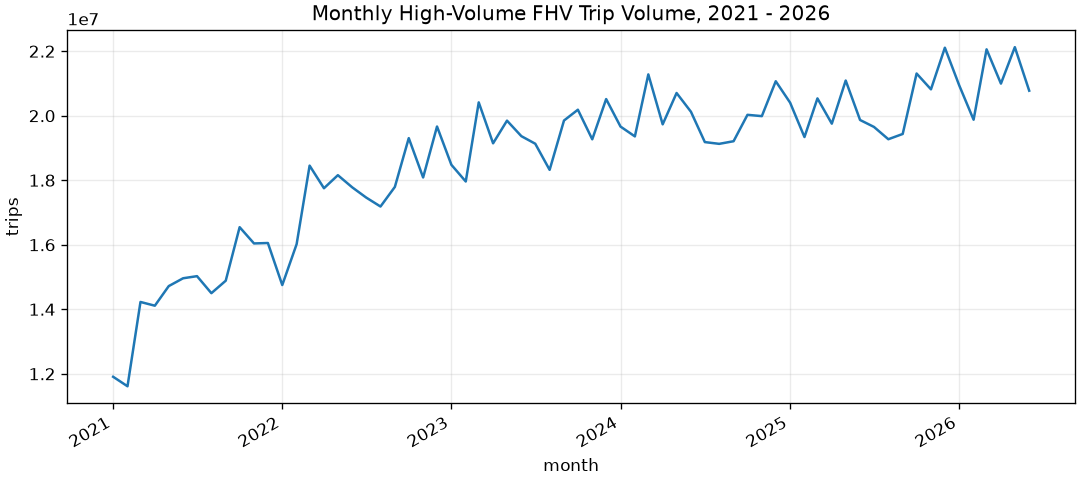

In [ ]:
fig = px.line(
    df_monthly, x="month", y="trips", title="Monthly High-Volume FHV Trip Volume, 2021 - 2026"
)
# fig.add_vline(x="2021-03-17", line_dash="dash", line_color="gray")
# fig.add_annotation(
#     x="2021-03-01",
#     y=1.02,
#     yref="paper",
#     showarrow=True,
#     text="Stimulus deposits begin",
#     bgcolor="cyan",
# )

# fig.add_vline(x="2021-07-01", line_dash="dash", line_color="gray")
# fig.add_annotation(
#     x="2021-07-01",
#     y=0.8,
#     yref="paper",
#     showarrow=True,
#     text="Child Tax Credit begins",
#     bgcolor="lightgreen",
# )

# fig.add_vline(x="2021-09-04", line_dash="dash", line_color="gray")
# fig.add_annotation(
#     x="2021-09-04", y=0.95, yref="paper", showarrow=True, text="FPUC $300 ends", bgcolor="salmon"
# )
# fig.update_layout(width=1000, height=500)
fig.show()

Later years have more trips than early 2021, with clear ups and downs between months. The city reopening after COVID probably explains part of the early growth, but the chart alone can't prove it. For modeling, the point is that both time patterns and a changing level matter.


## What can the recorded fares tell me?

I also look at base fares relative to distance and time. If I averaged fare per mile for every trip, tiny trips would get too much weight, so I start from monthly totals of fare, miles and time.


In [ ]:
df_passenger_fare_monthly = con.execute(f"""
    SELECT date_trunc('month', pickup_datetime) AS month,
           SUM(base_passenger_fare) AS total_fare, 
           SUM(trip_miles) AS total_miles,
           SUM(trip_time) AS total_seconds
    FROM '{PROJECT_ROOT}/data/bronze/fhvhv_tripdata_*.parquet'
    GROUP BY date_trunc('month', pickup_datetime)
    ORDER BY date_trunc('month', pickup_datetime)
    """).df()
pd.options.display.float_format = "{:,.2f}".format
df_passenger_fare_monthly

The monthly totals give me 66 rows to work with. Now I can divide total fare by total distance or duration, instead of averaging thousands of unstable short-trip ratios.


### Calculating fare per mile and fare per minute

I calculate both ratios from the monthly totals. They describe the trips that happened each month, not the price a rider would be quoted for the same trip.


In [ ]:
df_passenger_fare_monthly["price_per_mile"] = (
    df_passenger_fare_monthly.total_fare / df_passenger_fare_monthly.total_miles
)

df_passenger_fare_monthly["total_minutes"] = df_passenger_fare_monthly.total_seconds / 60
df_passenger_fare_monthly["price_per_minute"] = (
    df_passenger_fare_monthly.total_fare / df_passenger_fare_monthly.total_minutes
)

df_passenger_fare_monthly

For January 2021 it's about **$3.81 per mile** and **$1.08 per minute**. I compare them over time, keeping in mind that a different mix of trips can also move these ratios.


### Base fare per mile trend

I start with fare per mile. The monthly curve shows if the increase was gradual or happened in a few jumps.


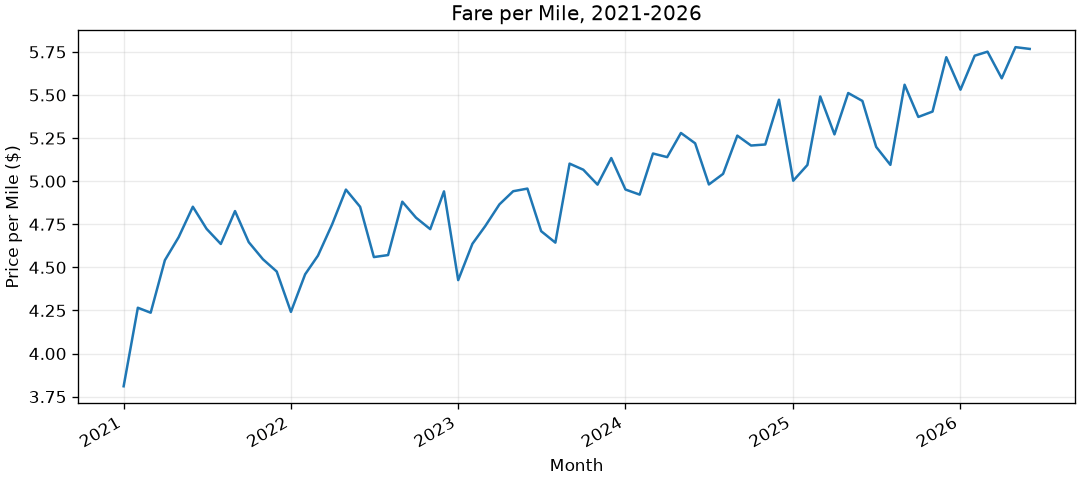

In [ ]:
fig = px.line(
    df_passenger_fare_monthly,
    x="month",
    y="price_per_mile",
    # x='month', y = 'earning per mile',
    #   title=dict(text="Fare per Mile, 2021-2026",
    #              font="Arial",
    #              color="#054F5E"),
    template="plotly_white",
)
fig.update_traces(line=dict(width=2, color="#057b95"))
fig.update_layout(
    title=dict(
        text="Fare per Mile, 2021-2026", font=dict(size=20, family="Roman", color="#074958")
    ),
)
fig.update_xaxes(showgrid=False, title="Month")
fig.update_yaxes(showgrid=True, gridcolor="#e2e8f0", title="Price per Mile ($)", tickprefix="$")
fig.show()

The ratio grows to about **$5.77 by June 2026**. That's a big change in base fare per mile, but it doesn't tell me how much the price of the same trip changed. Distance, trip mix and fare rules can all play a role.


### Base fare per minute trend

Next the same fares against total trip minutes, because a different denominator can show a different pattern.


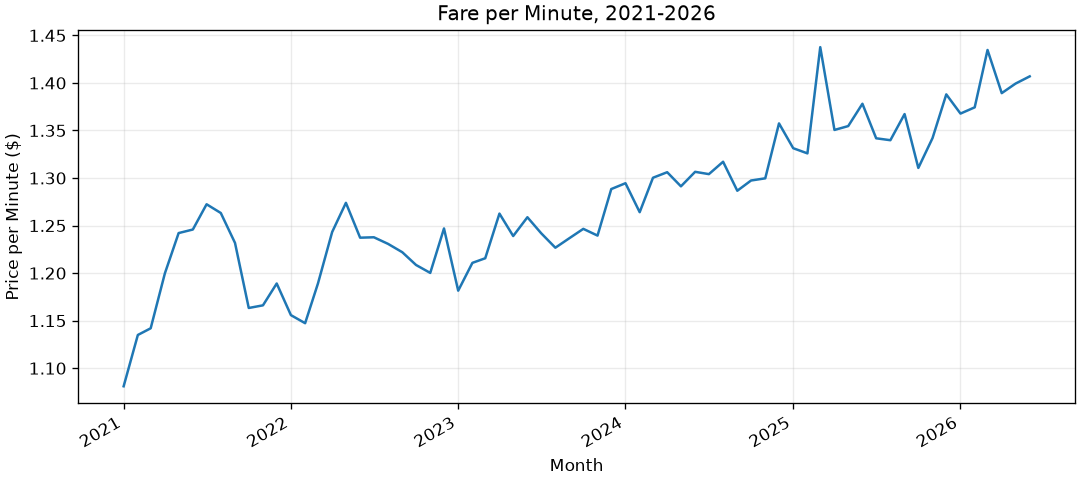

In [ ]:
fig = px.line(
    df_passenger_fare_monthly,
    x="month",
    y="price_per_minute",
    template="plotly_white",
)

fig.update_traces(line=dict(width=2, color="#057b95"))

fig.update_layout(
    title=dict(
        text="Fare per Minute, 2021-2026", font=dict(size=20, family="Roman", color="#074958")
    ),
)

fig.update_xaxes(showgrid=False, title="Month")

fig.update_yaxes(showgrid=True, gridcolor="#e2e8f0", title="Price per Minute ($)", tickprefix="$")

fig.show()

Fare per minute goes from about **$1.08 to $1.41**. I keep both summaries as background for future cost targets, not as a pricing schedule.


In [ ]:
# fig, ax = plt.subplots(figsize=(12, 6))
# sns.lineplot(data=df_passenger_fare_monthly, x="month", y="price_per_mile", ax=ax)
# ax.set_xlabel("Month")
# ax.set_ylabel("Fare per Mile")
# ax.set_title("Fare per Mile, 2021-2026")
# plt.show()

In [ ]:
# fig, ax = plt.subplots(figsize=(12, 6))
# sns.lineplot(data=df_passenger_fare_monthly, x="month", y="price_per_minute", ax=ax)
# ax.set_xlabel("Month")
# ax.set_ylabel("Price per Minute")
# ax.set_title("Fare per Minute, 2021-2026")
# plt.show()

In [ ]:
# fig = px.line(
#     df_passenger_fare_monthly, x="month", y="price_per_mile", title="Fare per Mile, 2021-2026"
# )
# fig = style_chart(fig, y_title="Price per Mile")
# fig.show()

## Where should I ask for the weather?

To connect trips with weather and events, I need geography for each zone. I load the TLC polygons and calculate one representative point per zone. Centroids are calculated in a projected coordinate system first and then converted back to latitude and longitude for the API requests.


In [ ]:
# 4 levels up: ingestion/ -> ride_demand/ -> src/ -> project root
# project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()


def download_zones_file() -> Path:
    # month_str = f"{month:02d}"
    filename = "tlc_zones.geojson"
    url = "https://data.cityofnewyork.us/api/geospatial/8meu-9t5y?method=export&format=GeoJSON"
    path_to_save = PROJECT_ROOT / "data" / "external" / filename

    if not path_to_save.exists():
        path_to_save.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(url, path_to_save)

    return path_to_save

In [ ]:
zones_path = download_zones_file()

In [ ]:
zones_path.read_text()[:300]

In [ ]:
zones_gdf = gpd.read_file(zones_path)
zones_gdf.head()

In [ ]:
zones_gdf_projected = zones_gdf.to_crs(epsg=2263)
zones_gdf["centroid"] = zones_gdf_projected.centroid.to_crs(epsg=4326)

In [ ]:
print(zones_gdf.crs)
print(zones_gdf_projected.crs)

EPSG:4326
EPSG:2263


In [ ]:
zones_gdf["centroid"] = zones_gdf_projected.centroid.to_crs(epsg=4326)
zones_gdf["centroid"].head()

The centroid gives each zone one consistent location for weather requests. Before using all of them I still need to check repeated zone IDs and zones missing from the geometry. One point is a practical summary of an area, not where every pickup happens.


For my first weather test I use three stations: Central Park (40.7789, -73.9692), LaGuardia (40.7794, -73.8803) and JFK (40.6413, -73.7781).


## My first try with three weather stations

My first idea was simple: give each zone the weather of its nearest station. But some outer zones end up far from any of the three, so I check the assignments before deciding if this simple approach is good enough.


In [ ]:
stations = {
    "Central Park": (40.7789, -73.9692),
    "LaGuardia": (40.7794, -73.8803),
    "JFK": (40.6413, -73.7781),
}

In [ ]:
len(zones_gdf)
zones_gdf["centroid"].iloc[0].x

-74.17400156372878

In [ ]:
def closest_station(centroid, stations=stations):
    distances = {}
    for name, (lat, lon) in stations.items():
        distance = haversine_distance(centroid.y, centroid.x, lat, lon)
        distances[name] = distance

    return min(distances, key=distances.get)

In [ ]:
zones_gdf["nearest_station"] = zones_gdf["centroid"].apply(closest_station)

In [ ]:
zones_gdf[["zone", "borough", "nearest_station"]].head(10)

In [ ]:
zones_gdf[zones_gdf["borough"] == "Staten Island"][["borough", "zone", "nearest_station"]].head(10)

Staten Island gets Central Park. It may be the closest of three, but it's a weak picture of Staten Island weather. So I drop the three-station idea and request weather by coordinates for each zone.


## What changes if each zone gets its own weather?

I request historical weather at each zone centroid from the [Open-Meteo archive endpoint](https://archive-api.open-meteo.com/v1/archive). This is actual past weather, good for describing completed rides. For forecasting later I'll need weather *forecasts* that existed before the target hour, and this table can't do that.


In [ ]:
# print(os.listdir(PROJECT_ROOT / "data" / "external" / "weather"))

In [ ]:
weather_paths = []

weather_dir = PROJECT_ROOT / "data" / "external" / "weather"

downloaded_ids = {int(f.split("_")[1]) for f in os.listdir(weather_dir) if f.startswith("zone_")}

missing = zones_gdf[~zones_gdf["locationid"].astype(int).isin(downloaded_ids)]

print(f"{len(missing)} zones still missing")

Every zone in the geometry list already has a saved file, so no new requests are needed. This doesn't tell me yet if the list has every pickup zone or if the saved series are complete.


In [ ]:
print(
    haversine_distance(40.7789, -73.9692, 40.6413, -73.7781)
)  # Central Park to JFK, should be ~14-15 miles

13.80524362280429


### Testing the per-zone weather downloader

I test the downloader on one zone first. If the file already exists, it should just return it without calling the API.


In [ ]:
# weather (use a zone you already have downloaded, so it's instant via the idempotency check)
test_path = download_weather_with_retry(
    location_id=1,
    centroid=zones_gdf.iloc[0]["centroid"],
    start_date="2021-01-01",
    stop_date="2026-06-30",
)
print(test_path)

The test returns zone 1's file from the weather folder. I use it next to look at the response structure.


### Downloading weather for missing zones

Only zones without a saved file need a request. I use retries for rate limits and keep failures visible, so one bad request doesn't stop the whole collection.


In [ ]:
missing = zones_gdf[~zones_gdf["locationid"].astype(int).isin(downloaded_ids)]  # recompute first
for _index, row in missing.iterrows():
    try:
        path = download_weather_with_retry(
            row["locationid"], row["centroid"], "2021-01-01", "2026-06-30"
        )
        weather_paths.append(path)
        print(f"Downloaded {path}")
    except Exception as e:
        print(f"FAILED zone {row['locationid']}: {e}")

This makes the collection easy to resume. Next I check what's inside the files, because a successful download doesn't mean a complete series with the right keys.


In [ ]:
# first_row = zones_gdf.iloc[0]
# test_path = download_weather(
#     first_row["locationid"], first_row["centroid"], "2021-01-01", "2026-06-30"
# )
# print(test_path)

Now I move from collecting files to building the hourly weather table.


## Combining the per-zone weather files

First I look at the `hourly` section of one response, to see how its timestamps and variables should become DataFrame columns.


In [ ]:
import json

with open(
    PROJECT_ROOT / "data" / "external" / "weather" / "zone_1_weather_2021-01-01_to_2026-06-30.json"
) as f:
    data = json.load(f)

print(data.keys())
print(data["hourly"].keys())

In [ ]:
weather_df = pd.DataFrame(data["hourly"])
weather_df.head()

In [ ]:
weather_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48168 entries, 0 to 48167
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   time            48168 non-null  object 
 1   temperature_2m  48168 non-null  float64
 2   precipitation   48168 non-null  float64
 3   rain            48168 non-null  float64
 4   snowfall        48168 non-null  float64
 5   wind_speed_10m  48168 non-null  float64
dtypes: float64(5), object(1)
memory usage: 2.2+ MB


In [ ]:
weather_df.time = pd.to_datetime(weather_df["time"])
weather_df.info()

In [ ]:
weather_df["location_id"] = 1

The example has **48,168 hourly rows**. I convert time to datetime and add the zone ID so I can connect it to pickups later.


### Building one weather table

I apply the same conversion to all files and put them together. The unit should be one zone and one hour, and I'll need to check that key before the join.


In [ ]:
all_weather = combine_weather_files(
    zones_gdf["locationid"].tolist(),
    "2021-01-01",
    "2026-06-30",
)
all_weather.shape

In [ ]:
all_weather.head()

In [ ]:
all_weather.to_parquet(PROJECT_ROOT / "data" / "silver" / "weather_hourly_all_zones.parquet")

In [ ]:
test_load = pd.read_parquet(PROJECT_ROOT / "data" / "silver" / "weather_hourly_all_zones.parquet")
test_load.shape

The combined table has about **12.7 million rows** and seven variables, and saving and reloading the Parquet works. That checks storage, but only the join will show if keys and coverage are right.


## Keeping the hours with no pickups

Now I build the main outcome: completed pickups in each zone and hour. Quiet hours with zero trips must be in the table too, not only hours with recorded trips.


#### My first count missed the quiet hours

My first grouping only returned hours with at least one pickup. Easy to miss, because every count it returned was correct. What was missing were the zone-hours with zero trips.


#### What the model would miss

A model can't learn from a zero hour that isn't in its table. So I add these combinations explicitly, and the target has quiet periods as well as busy ones.


#### Giving every zone and hour a row

I create every zone-hour combination and join observed counts onto this grid. Where there's no match and the trip data is complete, the count becomes zero. Missing source data is a different problem, and it should never become zero activity by the same shortcut.


In [ ]:
zone_pickups_complete = con.execute(f"""
    WITH hours AS (
        SELECT unnest(generate_series(
            TIMESTAMP '2021-01-01 00:00:00',
            TIMESTAMP '2026-06-30 23:00:00',
            INTERVAL 1 HOUR
        )) AS hour
    ),
    zones AS (
        SELECT LocationID AS location_id
        FROM read_csv_auto('{PROJECT_ROOT}/data/external/taxi_zone_lookup.csv')
        WHERE LocationID NOT IN (264, 265)
    ),
    grid AS (
        SELECT h.hour, z.location_id
        FROM hours h
        CROSS JOIN zones z
    ),
    actual_pickups AS (
        SELECT date_trunc('hour', pickup_datetime) AS hour,
               PULocationID AS location_id,
               COUNT(*) AS total_pickups
        FROM '{PROJECT_ROOT}/data/bronze/fhvhv_tripdata_*.parquet'
        WHERE PULocationID NOT IN (264, 265)
        GROUP BY date_trunc('hour', pickup_datetime), PULocationID
    )
    SELECT
        grid.hour,
        grid.location_id,
        COALESCE(actual_pickups.total_pickups, 0) AS total_pickups
    FROM grid
    LEFT JOIN actual_pickups
        ON grid.hour = actual_pickups.hour
        AND grid.location_id = actual_pickups.location_id
    ORDER BY grid.hour, grid.location_id
    """).df()

In [ ]:
%%time
zone_pickups_hourly = con.execute(f"""
    SELECT date_trunc('hour', pickup_datetime) AS hour, 
            (PULocationID) AS location_id, 
            COUNT(*) AS total_pickups
    FROM '{PROJECT_ROOT}/data/bronze/fhvhv_tripdata_*.parquet'
    GROUP BY date_trunc('hour', pickup_datetime), (PULocationID)
    ORDER BY date_trunc('hour', pickup_datetime), (PULocationID)
    """).df()

In [ ]:
zone_pickups_complete.shape

(12668184, 3)

In [ ]:
zone_pickups_hourly.shape

(12132079, 3)

In [ ]:
old_sum_real_zones_only = zone_pickups_hourly[~zone_pickups_hourly["location_id"].isin([264, 265])][
    "total_pickups"
].sum()

new_sum = zone_pickups_complete["total_pickups"].sum()

print(old_sum_real_zones_only, new_sum, old_sum_real_zones_only == new_sum)

1229274774 1229274774 True


The full grid has **48,168 hours × 263 zones = 12,668,184 rows**. Total pickups stay exactly **1,229,274,774**, so the new rows are only the zero hours that were missing, not extra trips.


In [ ]:
zone_pickups_hourly = zone_pickups_complete.copy()

In [ ]:
zone_pickups_hourly.head()

,hour,location_id,total_pickups
0,2021-01-01,1,0
1,2021-01-01,2,0
2,2021-01-01,3,80
3,2021-01-01,4,138
4,2021-01-01,5,11


In [ ]:
print(zone_pickups_hourly["hour"].iloc[5])
print(zone_pickups_hourly["hour"].dtype)

In [ ]:
zone_pickups_hourly[zone_pickups_hourly["location_id"] == 3].head(10)

,hour,location_id,total_pickups
2,2021-01-01 00:00:00,3,80
265,2021-01-01 01:00:00,3,77
528,2021-01-01 02:00:00,3,79
791,2021-01-01 03:00:00,3,62
1054,2021-01-01 04:00:00,3,46
1317,2021-01-01 05:00:00,3,47
1580,2021-01-01 06:00:00,3,28
1843,2021-01-01 07:00:00,3,39
2106,2021-01-01 08:00:00,3,18
2369,2021-01-01 09:00:00,3,28


In [ ]:
zone_pickups_hourly.to_parquet(PROJECT_ROOT / "data" / "gold" / "zone_hour_pickups.parquet")

In [ ]:
test_load = pd.read_parquet(PROJECT_ROOT / "data" / "gold" / "zone_hour_pickups.parquet")
test_load.shape

## Temperature unit conversion

I keep Celsius and add Fahrenheit, because it's easier to read for NYC charts. Keeping the original field makes the change easy to trace.

$$
F = C \times \frac{9}{5} + 32
$$


In [ ]:
all_weather["temperature_f"] = all_weather.temperature_2m * (9 / 5) + 32

In [ ]:
all_weather.to_parquet(PROJECT_ROOT / "data" / "silver" / "weather_hourly_all_zones.parquet")

In [ ]:
all_weather[["temperature_2m", "temperature_f"]].head(3)

,temperature_2m,temperature_f
0,3.90,39.02
1,3.70,38.66
2,2.90,37.22


The sample gives 39.02 °F for 3.9 °C, as expected. Now I join weather with pickups and check that the join doesn't change the target size.


## Why did the weather join add rows?

Weather should add columns, not rows. I left-join it to the full grid on zone and hour and compare row counts and missing values right away.


In [ ]:
weather_joined = con.execute(f"""
    SELECT
        p.hour,
        p.location_id,
        p.total_pickups,
        w.temperature_f,
        w.precipitation,
        w.rain,
        w.snowfall,
        w.wind_speed_10m
    FROM '{PROJECT_ROOT}/data/gold/zone_hour_pickups.parquet' p
    LEFT JOIN '{PROJECT_ROOT}/data/silver/weather_hourly_all_zones.parquet' w
        ON p.location_id = w.location_id AND p.hour = w.time
""").df()

In [ ]:
print(weather_joined.shape)
print(weather_joined["temperature_f"].isnull().sum())

(12812688, 8)
144504


In [ ]:
weather_check = pd.read_parquet(
    PROJECT_ROOT / "data" / "silver" / "weather_hourly_all_zones.parquet"
)
print(weather_check.duplicated(subset=["location_id", "time"]).sum())

The first join changes the size: it adds **144,504 rows** and also leaves some temperatures missing. So there is more than one problem. I start with repeated weather keys, then look for zones with no match.


In [ ]:
weather_joined[weather_joined["temperature_f"].isnull()]["hour"].describe()

#### Working backward through the merge

I don't fill the missing values right away. Instead I check step by step: are zone-hour keys unique? Do ID types match? Does the geometry have the same zones as the pickup grid? These questions should separate the causes.


In [ ]:
dupes = weather_check[weather_check.duplicated(subset=["location_id", "time"], keep=False)]
print(dupes["location_id"].nunique())
print(dupes["location_id"].value_counts().head(10))

The duplicates are all in zones **103 and 56**. That's a good clue: repeated geography records are more likely than random duplicate hours showing up only in two zones.


In [ ]:
missing_weather_zones = set(zone_pickups_hourly["location_id"].unique()) - set(
    weather_check["location_id"].unique()
)

# print(missing_weather_zones)

In [ ]:
zones_gdf["locationid"].value_counts().head(10)

locationid
103    3
56     2
232    1
20     1
248    1
247    1
3      1
233    1
234    1
235    1
Name: count, dtype: int64

The geometry confirms it: zone 103 appears three times and zone 56 twice, so their weather was repeated too. I make the weather key unique at the level the pickup join expects.


In [ ]:
print(zone_pickups_hourly["location_id"].dtype)
print(weather_check["location_id"].dtype)

int64
object


In [ ]:
unique_zones = zones_gdf.drop_duplicates(subset="locationid")
print(len(unique_zones))  # should be 263, not 265+

In [ ]:
all_weather["location_id"] = all_weather["location_id"].astype(int)
all_weather.to_parquet(PROJECT_ROOT / "data" / "silver" / "weather_hourly_all_zones.parquet")

There's also a type problem: one location ID column is integer and the other is object. I make them the same before comparing coverage, so the same ID is recognized on both sides.


In [ ]:
all_weather = all_weather.drop_duplicates(subset=["location_id", "time"])
all_weather.to_parquet(PROJECT_ROOT / "data" / "silver" / "weather_hourly_all_zones.parquet")

With the same key types, I remove repeated zone-hour weather rows. This should fix the extra rows, but it can't create weather for zones that really are missing.


In [ ]:
weather_check2 = pd.read_parquet(
    PROJECT_ROOT / "data" / "silver" / "weather_hourly_all_zones.parquet"
)
missing_weather_zones = set(zone_pickups_hourly["location_id"].astype(int).unique()) - set(
    weather_check2["location_id"].astype(int).unique()
)
print(missing_weather_zones)

Three zones are still missing: **57, 104 and 105**. Now that duplicates and types are fixed, I can deal with these gaps directly.


In [ ]:
null_hours = weather_joined[weather_joined["temperature_f"].isnull()]["hour"]
print(null_hours.dt.hour.value_counts().head(10))

In [ ]:
print(zones_gdf[zones_gdf["locationid"].astype(int).isin([57, 105])])

In [ ]:
non_special_nulls = weather_joined[
    weather_joined["temperature_f"].isnull()
    & ~weather_joined["location_id"].isin([57, 105, 264, 265])
]
print(len(non_special_nulls))

In [ ]:
print(
    zone_pickups_hourly[zone_pickups_hourly["location_id"].isin([57, 105, 264, 265])][
        "total_pickups"
    ].sum()
)

pickup_zones_weather_missing = [
    57,
    104,
    105,
    264,
    265,
]  # was [57, 58, 105, 264, 265] -- 58 was a typo, real gap is 104
for zone in pickup_zones_weather_missing:
    total_pickups = zone_pickups_hourly[zone_pickups_hourly["location_id"] == zone][
        "total_pickups"
    ].sum()
    print(f"Total pickups in zone{zone}: {total_pickups}")

print(zone_pickups_hourly["total_pickups"].sum())

In [ ]:
weather_check2.head()

## Finding a weather proxy for zone 57

Zone 57 has no centroid in this reference. I use the weather of its neighbor zone 56 as a stand-in, so zone 57 stays in the dataset. I document this, because it's a replacement, not its own weather.


In [ ]:
zone57_replacement = weather_check2[weather_check2["location_id"] == 56].copy()
zone57_replacement.head()

In [ ]:
zone57_replacement["location_id"] = 57
zone57_replacement.head()

In [ ]:
weather_check3 = pd.concat([weather_check2, zone57_replacement], ignore_index=True)

In [ ]:
weather_check3[weather_check3["location_id"] == 57].head()

In [ ]:
print(weather_check3[weather_check3["location_id"] == 57].shape)

The proxy gives zone 57 the expected 48,168 rows. Coverage is fixed under this assumption, but the series still really belongs to zone 56.


## Keeping both replacements for zones 104 and 105

Zones 104 and 105 get zone 103's weather. First I check the donor's temperature coverage, then give each copy the right zone ID.


In [ ]:
weather_check3[weather_check3["location_id"] == 103]["temperature_f"].isnull().sum()

In [ ]:
for i in [104, 105]:
    zone_replacement = weather_check3[weather_check3["location_id"] == 103].copy()
    zone_replacement["location_id"] = i
    weather_check3 = pd.concat([weather_check3, zone_replacement], ignore_index=True)

My first loop rebuilt from the original table each time, so the second replacement erased the first one. Now I append to the updated table instead. This is exactly why I check both zones after the loop.


In [ ]:
print(weather_check3[weather_check3["location_id"] == 104].shape)
print(weather_check3[weather_check3["location_id"] == 105].shape)

Both zones now have all 48,168 hourly rows. I keep them as documented proxies, not as separate downloads.


In [ ]:
with open(
    PROJECT_ROOT / "data" / "external" / "weather" / "zone_1_weather_2021-01-01_to_2026-06-30.json"
) as f:
    sample = json.load(f)
print(sample["hourly_units"])

## Weather unit check and conversion

Before converting other units, I read the response metadata. Rain and precipitation are in millimeters, snowfall in centimeters and wind in kilometers per hour. I convert based on these declared units, not on what the variable names suggest.


In [ ]:
weather_check3["wind_speed_mph"] = weather_check3.wind_speed_10m * 0.621371
weather_check3["precipitation_in"] = weather_check3.precipitation * 0.0393701
weather_check3["rain_in"] = weather_check3.rain * 0.0393701
weather_check3["snowfall_in"] = weather_check3.snowfall * 0.393701

In [ ]:
weather_check3[
    [
        "wind_speed_10m",
        "wind_speed_mph",
        "precipitation",
        "precipitation_in",
        "rain",
        "rain_in",
        "snowfall",
        "snowfall_in",
    ]
].head(5)

In [ ]:
weather_check3[weather_check3["snowfall"] > 2].head()

In [ ]:
weather_check3[weather_check3["rain"] > 10].head()

## Trying the weather join again

Now with unique weather keys, matching ID types and the three proxy zones, I try the join again. I expect the same pickup grid, just with weather columns added.


In [ ]:
weather_check3.to_parquet(PROJECT_ROOT / "data" / "silver" / "weather_hourly_all_zones.parquet")

weather_joined = con.execute(f"""
    SELECT
        p.hour, 
        p.location_id, 
        p.total_pickups,
        w.temperature_f, 
        w.precipitation_in, 
        w.rain_in, 
        w.snowfall_in,
        w.wind_speed_mph
    FROM '{PROJECT_ROOT}/data/gold/zone_hour_pickups.parquet' p
    LEFT JOIN '{PROJECT_ROOT}/data/silver/weather_hourly_all_zones.parquet' w
        ON p.location_id = w.location_id AND p.hour = w.time
""").df()

print(weather_joined.shape)
print(weather_joined["temperature_f"].isnull().sum())

In [ ]:
zone_pickups_hourly.shape

(12132079, 3)

In [ ]:
print("Start:", weather_joined["hour"].min())
print("End:", weather_joined["hour"].max())

In [ ]:
remaining_nulls = weather_joined[weather_joined["temperature_f"].isnull()]
print(remaining_nulls["location_id"].value_counts())

This time the row count stays **12,668,184** and no temperatures are missing. Both problems from the first join are solved.


In [ ]:
weather_joined.head()

## What can I learn from the calendar alone?

Hour, weekday and month should capture a lot of the regular pickup cycle. I also add flags for weekends, weekday rush hours and weekend nights. These are explicit definitions I can test later, not an assumption that every flagged hour is busy.


In [ ]:
weather_joined["hour_of_day"] = weather_joined.hour.dt.hour
weather_joined["day_of_week"] = weather_joined.hour.dt.day_of_week
weather_joined["is_weekend"] = weather_joined["day_of_week"].isin([5, 6])
weather_joined["month"] = weather_joined.hour.dt.month

In [ ]:
weather_joined[["hour", "day_of_week", "is_weekend", "hour_of_day"]].head(10)

In [ ]:
weekday_rush = ~weather_joined["is_weekend"]
morning_rush = weather_joined.hour_of_day.between(7, 9)
evening_rush = weather_joined.hour_of_day.between(16, 18)
weather_joined["is_weekday_rush_hour"] = weekday_rush & (morning_rush | evening_rush)

In [ ]:
weekend_night = weather_joined["is_weekend"]
late_hours = (weather_joined["hour_of_day"] >= 22) | (weather_joined["hour_of_day"] <= 2)
weather_joined["is_weekend_night"] = weekend_night & late_hours

In [ ]:
weather_joined.head()

In [ ]:
print(
    weather_joined[weather_joined["is_weekday_rush_hour"]]["day_of_week"].unique()
)  # should only show 0-4, never 5 or 6
print(
    weather_joined[weather_joined["is_weekend_night"]]["day_of_week"].unique()
)  # should only show 5 or 6

Weekday and weekend checks match the rules. Weekend night here means Saturday and Sunday nights, which is worth saying, because a Friday-night definition would be different.


## Holiday features

Some dates don't behave like normal weekdays or weekends. I add New York official and observed holidays, and a separate flag for some unofficial special dates. Keeping them separate makes later results easier to read.


In [ ]:
us_holidays = holidays.US(state="NY", years=range(2021, 2027))
print(list(us_holidays.items())[:5])

In [ ]:
weather_joined.hour.dt.date[:5]

In [ ]:
weather_joined["is_holiday"] = weather_joined["hour"].dt.date.apply(lambda day: day in us_holidays)

In [ ]:
unofficial_holidays_days = {
    (10, 31),  # halloween
    (12, 31),  # new year's eve
    (1, 1),  # new year's day
    (3, 17),  # st patrick's day
}

weather_joined["is_unofficial_holiday"] = weather_joined["hour"].dt.date.apply(
    lambda d: (d.month, d.day) in unofficial_holidays_days
)

In [ ]:
print(
    weather_joined[weather_joined["hour"].dt.date == pd.Timestamp("2022-07-04").date()][
        "is_holiday"
    ].unique()
)

July 4, 2022 is flagged correctly, so date matching works. Next is another calendar problem: the repeated daylight-saving hour.


## Daylight saving time correction

When clocks go back in November, the local 1 AM label covers two real hours. Simple aggregation adds their pickups together and that row looks unusually high. Here I fix it using neighboring weeks.

This is fine for describing history, but using a *later* week is a problem for forecasting. Before I can say every lag could have been built at forecast time, I need to redo this with UTC-based counts or a past-only rule.


In [ ]:
dst_dates = [
    "2021-11-07 01:00:00",
    "2022-11-06 01:00:00",
    "2023-11-05 01:00:00",
    "2024-11-03 01:00:00",
    "2025-11-02 01:00:00",
]

dst_date_list = [pd.Timestamp(d).date() for d in dst_dates]

is_dst_row = (weather_joined["hour"].dt.date.isin(dst_date_list)) & (
    weather_joined["hour_of_day"] == 1
)
is_dst_row.sum()

In [ ]:
seven_days = pd.Timedelta("7D")

after_lookup = weather_joined[["hour", "location_id", "total_pickups"]].copy()
after_lookup["hour"] = after_lookup["hour"] - seven_days
after_lookup = after_lookup.rename(columns={"total_pickups": "after_pickups"})

before_lookup = weather_joined[["hour", "location_id", "total_pickups"]].copy()
before_lookup["hour"] = before_lookup["hour"] + seven_days
before_lookup = before_lookup.rename(columns={"total_pickups": "before_pickups"})

weather_joined = weather_joined.merge(after_lookup, on=["hour", "location_id"], how="left")
weather_joined = weather_joined.merge(before_lookup, on=["hour", "location_id"], how="left")

In [ ]:
replacement = weather_joined.loc[is_dst_row, ["before_pickups", "after_pickups"]].mean(axis=1)
print("rows with no valid before/after neighbor:", replacement.isna().sum())

valid_replacement = replacement.dropna()
weather_joined.loc[valid_replacement.index, "total_pickups"] = valid_replacement.round().astype(int)

In [ ]:
for event in dst_dates:
    dst_event_pickups = weather_joined[
        (weather_joined["hour"] == event) & (weather_joined["location_id"] == 79)
    ]["total_pickups"]

    week_after_event_pickups = weather_joined[
        (weather_joined["hour"] == pd.Timestamp(event) + pd.Timedelta(days=7))
        & (weather_joined["location_id"] == 79)
    ]["total_pickups"]

    pickups_ratio = dst_event_pickups.iloc[0] / week_after_event_pickups.iloc[0]
    print(pickups_ratio)

In [ ]:
weather_joined = weather_joined.drop(columns=["after_pickups", "before_pickups"])

## First try for concert data: Ticketmaster

I first try Ticketmaster for concerts and other big events. Venue coordinates can be mapped to TLC zones, but the source also needs to cover the past years of my trip data.


### Testing the Ticketmaster API

I test a few historical requests before building a bigger downloader around it.


In [ ]:
venues = pd.DataFrame(
    {
        "venue_name": [
            "Madison Square Garden",
            "Barclays Center",
            "Yankee Stadium",
            "Citi Field",
            "USTA National Tennis Center",
        ],
        "latitude": [40.7503, 40.6827, 40.8296, 40.7570, 40.7500],
        "longitude": [-73.9933, -73.9752, -73.9262, -73.8458, -73.8475],
    }
)
venues

In [ ]:
zones_gdf.head()

In [ ]:
points = []
for i in range(len(venues)):
    point = Point(venues.iloc[i]["longitude"], venues.iloc[i]["latitude"])
    points.append(point)

# points

matching_location_ids = []
for p in range(len(points)):
    match = zones_gdf[zones_gdf.contains(points[p])]
    matching_location_ids.append(
        [
            venues["venue_name"].iloc[p],
            match["locationid"].iloc[0],
            match["zone"].iloc[0],
            match["borough"].iloc[0],
        ]
    )

venues_plus_location_ids = pd.DataFrame(
    matching_location_ids, columns=(["venue_name", "location_id", "zone", "borough"])
)
venues_plus_location_ids["location_id"] = venues_plus_location_ids["location_id"].astype(int)
venues_plus_location_ids

In [ ]:
def search_venue(keyword):
    response = requests.get(
        "https://app.ticketmaster.com/discovery/v2/venues.json",
        params={"keyword": keyword, "apikey": TICKETMASTER_API_KEY, "stateCode": "NY"},
    )
    return response.json()


venue_names = [
    "Madison Square Garden",
    "Barclays Center",
    "Yankee Stadium",
    "CitiField",
    "Billie Jean King National Tennis Center",
]

for name in venue_names:
    result = search_venue(name)
    venues = result.get("_embedded", {}).get("venues", [])
    print(f"--- {name} ---")
    for v in venues[:3]:  # show a few candidates, in case of ambiguous matches
        city = v.get("city", {}).get("name")
        print(f"  {v.get('name')} | id={v.get('id')} | {city}")
    print()

In [ ]:
def generate_quarters(start_year=2021, start_quarter=1, end_year=2026, end_quarter=2):
    quarters = []
    year, q = start_year, start_quarter
    while (year, q) <= (end_year, end_quarter):
        start_month = (q - 1) * 3 + 1
        end_month = start_month + 2
        start = f"{year}-{start_month:02d}-01T00:00:00Z"
        # last day of end_month, safely (handles Feb/30-day months)
        end_date = pd.Timestamp(year=year, month=end_month, day=1) + pd.offsets.MonthEnd(0)
        end = end_date.strftime("%Y-%m-%dT23:59:59Z")
        quarters.append((start, end))
        q += 1
        if q > 4:
            q = 1
            year += 1
    return quarters

In [ ]:
def fetch_ticketmaster_events(venue_name, venue_id, start_date, end_date, api_key):
    """
    Fetch all events for one venue within one date-range chunk.
    Saves raw JSON to disk; skips the API call entirely if that file
    already exists (same idempotent pattern as the weather downloader).
    """
    EVENTS_DIR = PROJECT_ROOT / "data" / "external" / "events"
    EVENTS_DIR.mkdir(exist_ok=True, parents=True)
    safe_name = venue_name.lower().replace(" ", "_")
    url = "https://app.ticketmaster.com/discovery/v2/events.json"
    filepath = EVENTS_DIR / f"{safe_name}_{start_date[:10]}_to_{end_date[:10]}.json"

    if not filepath.exists():
        result = requests.get(
            url,
            params={
                "apikey": api_key,
                "venueId": venue_id,
                "startDateTime": start_date,
                "endDateTime": end_date,
                "size": 200,
            },
        )
        data = result.json()

        if "errors" in data:
            print(f"ERROR fetching {venue_name} {start_date[:10]}: {data['errors'][0]['detail']}")
            return  # don't save — next run will retry this one

        total_pages = data.get("page", {}).get("totalPages", 1)
        if total_pages > 1:
            print(
                f"WARNING: {venue_name} {start_date[:10]} has {total_pages} pages — some events may be missing"
            )

        with open(filepath, "w") as f:
            json.dump(data, f)

        print(f"Fetched: {venue_name}, {start_date[:10]} to {end_date[:10]}")
    else:
        print(f"Already cached, skipping: {venue_name}, {start_date[:10]} to {end_date[:10]}")

In [ ]:
fetch_ticketmaster_events(
    "Madison square garden",
    "KovZpZA7AAEA",
    "2026-08-10T00:00:00Z",
    "2026-09-10T00:00:00Z",
    TICKETMASTER_API_KEY,
)

The requests return upcoming events, but not the history I need. An empty historical response doesn't mean no events happened, so I look for another source.


## Can ESPN supply the historical games?

ESPN looks better for historical sports schedules. I start with the Knicks to see if the response has dates, venues and start times that overlap my trip history. Then I can decide how to estimate when fans leave.


In [ ]:
response = requests.get(
    "https://site.web.api.espn.com/apis/site/v2/sports/basketball/nba/teams/ny/schedule",
    params={"season": 2023},
)
data = response.json()
print(len(data.get("events", [])), "games found")
print(data.get("events", [{}])[0].get("date") if data.get("events") else "no events")

The response has **82 games** for the 2022–2023 season. ESPN labels it 2023, even though the first game is in October 2022. So I join on actual game dates, not on the season label.


### Finding the correct ESPN team IDs

Before collecting more teams I look up their ESPN IDs. Safer than guessing abbreviations and finding out later I downloaded the wrong schedule.


In [ ]:
def list_teams(sport, league):
    response = requests.get(f"https://site.api.espn.com/apis/site/v2/sports/{sport}/{league}/teams")
    data = response.json()
    teams = data["sports"][0]["leagues"][0]["teams"]
    for t in teams:
        info = t["team"]
        print(f"{info['displayName']:30} id={info['id']:6} abbrev={info['abbreviation']}")

In [ ]:
# list_teams("basketball", "nba")   # find Knicks and Nets
# list_teams("hockey", "nhl")       # find Rangers and Islanders
# list_teams("baseball", "mlb")     # find Yankees and Mets

### Looking at one game record

I look at one full record first. Useful fields are start time, venue, home/away and status. Attendance looks interesting too, but I have to separate facts known after the game from inputs known before a forecast.


In [ ]:
import json

# with open(PROJECT_ROOT / "data" / "external" / "events" / "new_york_knicks_2023_schedule.json") as f:
#     data = json.load(f)

one_event = data["events"][1]
print(list(one_event.keys()))
print()
print(json.dumps(one_event, indent=2)[:2000])  # first chunk, so it's readable

Home/away lets me keep only games at the local venue. Attendance and final status describe what happened afterwards, so a live forecasting version would need to handle them differently.


### Was the game actually played?

A scheduled game can be postponed or canceled. I check status fields, so I don't treat every schedule entry as a played game. For real forecasts I would need the status known at that time, not the final outcome.


In [ ]:
print(one_event["competitions"][0].get("status"))

The example is marked final and completed. Good for checking historical games, but it doesn't mean completion was known before the game started.


### Building a reusable schedule downloader

Now I turn the working request into a downloader for team, sport, league and season. Raw schedules are cached, so if I change the parsing I don't need to fetch everything again.


In [ ]:
def fetch_espn_schedule(team_name, sport, league, team_id, season):
    """
    Fetch one team's full schedule for one season. Saves raw JSON to
    disk; skips the API call if that file already exists — same
    idempotent pattern as download_weather_with_retry and
    fetch_ticketmaster_events.
    """
    EVENTS_DIR = PROJECT_ROOT / "data" / "external" / "events"
    EVENTS_DIR.mkdir(exist_ok=True, parents=True)
    safe_name = team_name.lower().replace(" ", "_")
    filepath = EVENTS_DIR / f"{safe_name}_{season}_schedule.json"
    url = f"https://site.web.api.espn.com/apis/site/v2/sports/{sport}/{league}/teams/{team_id}/schedule"

    # TODO: if filepath already exists, print a skip message and return
    if not filepath.exists():
        result = requests.get(url, params={"season": season})
        data = result.json()

        events_key = data.get("events", [])
        if len(events_key) == 0:
            print(f"WARNING: {team_name} {season} has zero events")
            return

        with open(filepath, "w") as f:
            json.dump(data, f)

        print(f"Downloaded {team_name}'s {season} season")
    else:
        print(f"Already downloaded, skipping: {team_name}, season {season}")

### Choosing the NYC teams

I start with the Knicks, Nets, Rangers, Yankees and Mets, all with home venues inside NYC taxi zones. The Giants and Jets play in New Jersey, and the Islanders need a more complicated venue history, so I leave them out for now.


In [ ]:
teams = [
    ("New York Knicks", "basketball", "nba", "18"),
    ("Brooklyn Nets", "basketball", "nba", "17"),
    ("New York Rangers", "hockey", "nhl", "13"),
    ("New York Yankees", "baseball", "mlb", "10"),
    ("New York Mets", "baseball", "mlb", "21"),
]

for team_name, sport, league, team_id in teams:
    for season in range(2021, 2027):
        fetch_espn_schedule(team_name, sport, league, team_id, season)

The schedules are already saved, so the downloader skips new requests. Five teams across six seasons should give 30 files. I check that before parsing games.

$$
5 \times 6 = 30
$$


In [ ]:
schedule_files = [
    f
    for f in (PROJECT_ROOT / "data" / "external" / "events").iterdir()
    if f.name.endswith("_schedule.json")
]
print(len(schedule_files))

All 30 files are there. Now I look at the records themselves, where date ranges and game status can still cause problems.


### Approximating when spectators leave

The schedule gives the start time, but pickups probably rise when fans leave. So I estimate the end from start time plus an assumed game length, and create a post-game window. This is my modeling assumption, not an observed ending time.


In [ ]:
def estimate_game_duration(sport, game_date):
    if sport == "baseball":
        cutoff = pd.Timestamp("2023-01-01", tz="UTC")
        return (
            pd.Timedelta(hours=2, minutes=40)
            if game_date >= cutoff
            else pd.Timedelta(hours=3, minutes=10)
        )
    elif sport == "basketball":
        return pd.Timedelta(hours=2, minutes=15)
    elif sport == "hockey":
        return pd.Timedelta(hours=2, minutes=30)

I assume 2 h 15 min for basketball, 2 h 30 min for hockey, and for baseball 3 h 10 min before 2023 and 2 h 40 min after (the pitch clock made games shorter). Later model comparisons can show if these windows help prediction, but they can't tell me when each game really ended.


### Why I didn't include the New York Islanders

The Islanders changed home venue during my history period, so one fixed team-to-zone lookup would be wrong. I'd need the actual venue for each date before adding them.


## Building the historical game dataset

I connect each team to its venue's TLC zone and keep this lookup in one place. Teams sharing an arena share a zone, so after expanding events I'll need a unique zone-hour key.


In [ ]:
team_zone_map = {
    "New York Knicks": {"sport": "basketball", "location_id": 186, "team_id": "18"},
    "New York Rangers": {"sport": "hockey", "location_id": 186, "team_id": "13"},
    "Brooklyn Nets": {"sport": "basketball", "location_id": 181, "team_id": "17"},
    "New York Yankees": {"sport": "baseball", "location_id": 247, "team_id": "10"},
    "New York Mets": {"sport": "baseball", "location_id": 93, "team_id": "21"},
}

### Extracting the fields I need from each game

The parser keeps the fields I need for home games and skips away games. Event IDs let me check for duplicates, and scheduled start times are the base for the post-game window.


In [ ]:
def extract_game_data(event, team_id):
    competition = event["competitions"][0]
    competitors = competition["competitors"]

    home_competitor = None
    for c in competitors:
        if c["homeAway"] == "home":
            home_competitor = c

    if home_competitor["id"] != team_id:
        return None  # this team was away, not home — skip it

    event_id = event["id"]
    start_time = event["date"]
    season_year = event["season"]["year"]
    season_type = event["seasonType"]["name"]
    attendance = competition["attendance"]

    return {
        "event_id": event_id,
        "start_time": start_time,
        "season_year": season_year,
        "season_type": season_type,
        "attendance": attendance,
    }


test_example = extract_game_data(one_event, 21)
test_example

### Processing a full team schedule

I run the parser on one full saved schedule and add the team's sport and venue zone. If it works for one file, the other team-season files follow the same way.


In [ ]:
def process_schedule_file(filepath, team_name):
    with open(filepath) as f:
        data = json.load(f)
        # data_df = pd.DataFrame(data['events'])

    team_info = team_zone_map[team_name]
    games = []

    for event in data["events"]:
        home_game = extract_game_data(event, team_info["team_id"])
        if home_game is not None:
            home_game["team_name"] = team_name
            home_game["team_id"] = team_info["team_id"]
            home_game["location_id"] = team_info["location_id"]
            home_game["sport"] = team_info["sport"]
            games.append(home_game)
    return games

### Combining all teams and seasons

Now I combine all parsed schedules and convert start times to datetime. Time zone needs to be right before I group games by local date or create hourly flags.


In [ ]:
all_games = []

for team_name, _info in team_zone_map.items():
    for season in range(2021, 2027):
        safe_name = team_name.lower().replace(" ", "_")
        filepath = EVENTS_DIR / f"{safe_name}_{season}_schedule.json"
        all_games.extend(process_schedule_file(filepath, team_name))

games_df = pd.DataFrame(all_games)
games_df["start_time_et"] = pd.to_datetime(games_df["start_time"]).dt.tz_convert("America/New_York")
print(games_df.shape)
print(games_df["team_name"].value_counts())

The combined table has **1,739 home games**. Baseball totals are above my rough expectation of 81 home games × 6 seasons, which needs a closer look before I decide if they're correct or duplicated.

$$
81 \times 6 = 486
$$


Expected totals are only a rough check. Season length, status and rescheduling can all change the count, so I look at the records before treating extra games as real.


## Why are the baseball counts higher than expected?

My first guess was playoff games. I check the season-type field before accepting that.


In [ ]:
games_df[games_df["team_name"].isin(["New York Yankees", "New York Mets"])][
    "season_type"
].value_counts()

Wrong guess: all **1,018** Yankees and Mets records are regular season. Next I look for repeated event IDs, because the same game listed twice would be the most direct explanation.


In [ ]:
games_df[games_df["team_name"].isin(["New York Yankees", "New York Mets"])][
    "event_id"
].duplicated().sum()

No repeated event IDs. That rules out exact duplicates, but not postponed and rescheduled games with different IDs. I break counts down by season and look at dates.


In [ ]:
games_df[games_df["team_name"].isin(["New York Yankees", "New York Mets"])].groupby(
    ["team_name", "season_year"]
).size()

Several seasons are above the expected number, so it's not just one strange year. Next I look at dates with more than one game.


In [ ]:
mets_2021 = games_df[(games_df["team_name"] == "New York Mets") & (games_df["season_year"] == 2021)]
mets_2021["start_time"].str[:10].duplicated().sum()

The first date check finds 11 same-day groups, but it uses UTC, and a late New York game can fall on the next UTC date. I convert to local time before deciding which games share a day.


In [ ]:
mets_2021[mets_2021["start_time_et"].dt.date.duplicated(keep=False)].sort_values("start_time_et")[
    ["event_id", "start_time_et"]
]

In local time there are **nine same-day pairs** with different IDs and start times, so they look like real doubleheaders, not duplicates. But doubleheaders only move games between dates, they don't explain more than 81 home games in a season. Completion and rescheduling history still need a review.


### When do pickups rise after a game?

I add the assumed game length to the New York start time and flag the next hour as the approximate time fans leave. New York switches between standard and daylight time, so I can't call the whole series EST.

$$
\text{window start} = \text{game start} + \text{assumed length}, \qquad \text{window end} = \text{window start} + 1\text{ hour}
$$


In [ ]:
games_df["duration"] = games_df.apply(
    lambda row: estimate_game_duration(row["sport"], row["start_time_et"]), axis=1
)
games_df["estimated_end"] = games_df["start_time_et"] + games_df["duration"]
games_df["window_end"] = games_df["estimated_end"] + pd.Timedelta(hours=1)

In [ ]:
games_df.iloc[:, -4:].head()

A window like 9:45–10:45 PM touches two hourly buckets. If I only flag 9 PM I miss most of the window, so I flag every hour the window overlaps.


In [ ]:
hours = pd.date_range(start="2022-01-01 21:00", end="2022-01-02 01:00", freq="h")
print(hours)

### Turning the post-game window into hourly buckets

A helper expands each window into hourly timestamps. The endpoint matters: a window that ends exactly at 11 PM shouldn't flag the 11 PM hour.


In [ ]:
def get_affected_hours(estimated_end, window_end):
    """
    Given a game's estimated_end and window_end (both tz-aware),
    return every hour-bucket (as naive local timestamps, matching
    weather_joined) that overlaps the window at all.
    """
    # strip timezone info from both estimated_end and window_end
    estimated_end_strip_tz = estimated_end.tz_localize(None)
    window_end_strip_tz = window_end.tz_localize(None)

    # find the FIRST hour bucket to check — the hour containing
    # estimated_end, rounded DOWN to the top of that hour
    estimated_end_floor_hour = estimated_end_strip_tz.floor("h")
    window_end_floor_hour = window_end_strip_tz.floor("h")

    # build a list of candidate hours from that first bucket up
    window_hours = pd.date_range(
        start=estimated_end_floor_hour, end=window_end_floor_hour, freq="h"
    )
    filtered_hours = []
    for h in window_hours:
        if h < window_end_strip_tz and h + pd.Timedelta(hours=1) > estimated_end_strip_tz:
            filtered_hours.append(h)
    window_hours = filtered_hours

    return window_hours

### Building the zone-hour sports table

Expanding the windows gives records at the same level as the main table: venue zone and hour. One game can create two rows, so game counts and flagged hours are different things.


In [ ]:
demand_pairs = []
for _idx, row in games_df.iterrows():
    affected_hours = get_affected_hours(row["estimated_end"], row["window_end"])
    for h in affected_hours:
        demand_pairs.append({"location_id": row["location_id"], "hour": h})

demand_df = pd.DataFrame(demand_pairs)

In [ ]:
demand_df.shape

(3443, 2)

There are **3,443** event-hour records before screening. I check their dates before joining with a trip table that ends in June 2026.


### Checking the sports date range

Sports seasons and my trip period don't start and end at the same time. Some games fall before January 2021 or after June 2026, and I remove only those, they aren't invalid games.


In [ ]:
extra = demand_df[demand_df["hour"] > "2026-06-30 23:00:00"].copy()
extra.shape

In [ ]:
extra.head()

In [ ]:
demand_df[demand_df["hour"] < "2021-01-01"].shape[0]

10

**10** event-hour records are before the period and **164** after. Removing them lines up the coverage with the pickup table.


In [ ]:
demand_df = demand_df[
    (demand_df["hour"] >= "2021-01-01") & (demand_df["hour"] <= "2026-06-30 23:00:00")
]

### Checking for duplicate zone-hour event records

Before merging I check if a zone-hour appears twice. Two events can really overlap, but a yes/no flag needs only one row, otherwise the join would duplicate pickups.


In [ ]:
demand_df.duplicated(subset=["location_id", "hour"]).sum()

np.int64(1)

One key is repeated. I keep one row, because the feature asks if there is a post-game window, not how many events made it.


In [ ]:
demand_df = demand_df.drop_duplicates(subset=["location_id", "hour"])
demand_df.duplicated(subset=["location_id", "hour"]).sum()

Keys are unique now. I join the sports flag onto the pickup-weather table and set unmatched rows to false. The pickup row count should stay the same.


In [ ]:
demand_df["is_post_game_demand"] = True

weather_joined_sports = weather_joined.merge(
    demand_df[["location_id", "hour", "is_post_game_demand"]],
    on=["location_id", "hour"],
    how="left",
)
weather_joined_sports["is_post_game_demand"] = weather_joined_sports["is_post_game_demand"].fillna(
    False
)

In [ ]:
weather_joined_sports["is_post_game_demand"].sum()

np.int64(3268)

The result has **3,268 flagged zone-hours**. That's not the number of games, because windows can cover two hours and events can share a key. The count matches the cleaned event-hour table.


In [ ]:
weather_joined_sports[
    (weather_joined_sports["is_post_game_demand"])
    & (weather_joined_sports["hour"] > "2023-01-01 21:00:00")
].head(5)

### Do the flagged hours actually look busier?

The merge works, but do these windows really point to busier hours? I compare flagged hours with the same zone and hour a week before and a week after. This is only a description, because the week after can't be used in a real-time forecast.


### What happens at the same hour in nearby weeks?

The average of the week before and after keeps zone, weekday and clock hour the same. I look at ratios first and then differences, because dividing by a tiny baseline can make a normal increase look huge.

$$
\text{baseline} = \frac{\text{pickups week before} + \text{pickups week after}}{2}, \qquad \text{ratio} = \frac{\text{post-game pickups}}{\text{baseline}}
$$


In [ ]:
comparisons = []
for _, row in weather_joined_sports[weather_joined_sports["is_post_game_demand"]].iterrows():
    week_before = row["hour"] - pd.Timedelta(days=7)
    week_after = row["hour"] + pd.Timedelta(days=7)

    before_val = weather_joined_sports[
        (weather_joined_sports["location_id"] == row["location_id"])
        & (weather_joined_sports["hour"] == week_before)
    ]["total_pickups"]
    after_val = weather_joined_sports[
        (weather_joined_sports["location_id"] == row["location_id"])
        & (weather_joined_sports["hour"] == week_after)
    ]["total_pickups"]

    if len(before_val) and len(after_val):
        baseline = (before_val.iloc[0] + after_val.iloc[0]) / 2
        if baseline > 0:
            comparisons.append(
                {
                    "location_id": row["location_id"],
                    "hour": row["hour"],
                    "event_pickups": row["total_pickups"],
                    "baseline": baseline,
                    "ratio": row["total_pickups"] / baseline,
                }
            )

comparisons_df = pd.DataFrame(comparisons)
comparisons_df["ratio"].describe()

The median ratio is about **1.52**, but the mean is **3.10** and the maximum above **89**. A few extreme ratios pull the mean up, so I look at their baselines before calling this a typical event pattern.


In [ ]:
comparisons_df.sort_values("ratio", ascending=False).head(10)

### Looking at the extreme ratios

All the huge ratios come from **zone 93**. In one case 134 pickups are compared with a baseline of 1.5. The increase may be real, but "89 times normal" is mostly the tiny denominator talking.


In [ ]:
comparisons_df[comparisons_df["ratio"] == 0]

In [ ]:
comparisons_df.groupby("location_id")["ratio"].median()

location_id
93    3.19
181   1.30
186   1.25
247   1.69
Name: ratio, dtype: float64

### A closer look at zone 93

Some flagged hours have no increase at all, one even has zero pickups against a baseline of six. So the flag doesn't promise a surge. I compare the venue zones to see how their normal activity differs.


In [ ]:
tlc_zones = pd.read_csv(PROJECT_ROOT / "data" / "external" / "taxi_zone_lookup.csv")

sports_zones = comparisons_df["location_id"].unique()

zones_desc = tlc_zones.loc[
    tlc_zones["LocationID"].isin(sports_zones), ["LocationID", "Borough", "Zone"]
]

zones_desc

Zone 93 is Flushing Meadows–Corona Park, around Citi Field. Normal hours there are quiet, so event ratios get much bigger than in busy neighborhoods. That's a reason to report absolute changes together with ratios.


### Comparing pickups across sports zones

I compare normal pickup levels, variation and share of zeros across the sports zones. This should show if zone 93's ratios come from its low baseline or from its event counts.

$$
\text{dispersion ratio} = \frac{\text{variance of pickups}}{\text{mean pickups}}
$$


In [ ]:
def summarize_target_distribution(df, target_col="total_pickups", group_cols=None):
    if group_cols is None:
        df = df.copy()
        df["_dummy"] = 1
        group_cols = ["_dummy"]

    summary = df.groupby(group_cols).agg(
        n_rows=(target_col, "count"),
        mean=(target_col, "mean"),
        variance=(target_col, "var"),
        zero_frac=(target_col, lambda x: (x == 0).mean()),
    )
    summary["dispersion_ratio"] = summary["variance"] / summary["mean"]
    summary = summary.reset_index()

    if "_dummy" in summary.columns:
        summary = summary.drop(columns="_dummy")

    return summary

In [ ]:
result = summarize_target_distribution(weather_joined_sports, group_cols=["location_id"])
result[result["location_id"].isin([93, 181, 186, 247])]

Zone 93 averages about **19 pickups an hour**, far below the other sports zones, and about 4% of its hours are zero. One citywide ratio would hide this difference.


In [ ]:
comparisons_df[comparisons_df["location_id"] != 93]["ratio"].describe()

count   2,311.00
mean        1.57
std         0.66
min         0.30
25%         1.15
50%         1.40
75%         1.83
max         6.82
Name: ratio, dtype: float64

### Does the post-game pattern show up near other venues?

Without zone 93, the median ratio is about **1.40** and the mean **1.57**. The increase is still there, but the big gap between mean and median mostly disappears. Now back to zone 93, using differences instead.


### Zone 93 with pickup differences

For zone 93 I subtract the nearby-week baseline instead of dividing by it. A difference stays in pickups and is easier to judge when the baseline is near zero.

$$
\text{pickup difference} = \text{event-hour pickups} - \text{baseline}
$$


In [ ]:
comparisons_df[comparisons_df["location_id"] == 93]["event_pickups"].sub(
    comparisons_df[comparisons_df["location_id"] == 93]["baseline"]
).describe()

The median difference is about **87 pickups**, and the middle half is between 24 and 156. The big negative minimum surprised me more than another large positive value, so I look at those cases.


### Looking at the negative zone 93 cases

My guess was another game in a baseline week, which would raise the baseline and make this event look weak. I check the largest negative cases against nearby schedules.


In [ ]:
z93 = comparisons_df[comparisons_df["location_id"] == 93].copy()
z93["diff"] = z93["event_pickups"] - z93["baseline"]
z93.sort_values("diff").head(3)

### Another game doesn't explain these cases

Guess was wrong for the three largest negative cases, there are no games in their baseline weeks. Other events, uncertain game endings or just normal variation could explain them. Next I check if the pattern changes by hour.


In [ ]:
suspect_dates = ["2022-08-25", "2022-09-15", "2022-09-16"]

for d in suspect_dates:
    event_time = pd.Timestamp(d + " 23:00:00")
    week_before = event_time - pd.Timedelta(days=7)
    week_after = event_time + pd.Timedelta(days=7)

    nearby = games_df[
        (games_df["location_id"] == 93)
        & (
            games_df["start_time_et"]
            .dt.tz_localize(None)
            .between(week_before - pd.Timedelta(hours=6), week_before + pd.Timedelta(hours=6))
            | games_df["start_time_et"]
            .dt.tz_localize(None)
            .between(week_after - pd.Timedelta(hours=6), week_after + pd.Timedelta(hours=6))
        )
    ]
    print(d, "-> nearby control-week games:", len(nearby))

In [ ]:
z93 = comparisons_df[comparisons_df["location_id"] == 93].copy()
z93["hour_of_day"] = z93["hour"].dt.hour
z93["diff"] = z93["event_pickups"] - z93["baseline"]
z93.groupby("hour_of_day")["diff"].describe()

### The pattern changes by hour

The biggest median increases are around 9–10 PM, and by 11 PM the effect is much weaker. So one broad post-game flag may not be equally useful at every hour. It still doesn't give me the real ending time of each game.


In [ ]:
weather_joined_sports.shape

In [ ]:
weather_joined_sports.to_parquet(
    PROJECT_ROOT / "data" / "gold" / "zone_hour_pickups_weather.parquet"
)

## Historical concerts from setlist.fm

Since Ticketmaster didn't have the history, I use setlist.fm for past concerts. First I need the right venue records, because a correct date at the wrong venue would give a misleading local feature.


In [ ]:
headers = {"x-api-key": SETLISTFM_API_KEY_1, "Accept": "application/json"}

response = requests.get(
    "https://api.setlist.fm/rest/1.0/search/venues",
    headers=headers,
    params={"name": "Madison Square Garden"},
)
# print(response.json())

In [ ]:
data = response.json()
venues_example_df = pd.json_normalize(data["venue"])
venues_example_df.columns

In [ ]:
venue_schema = json_schema(data["venue"][0])

print(json.dumps(venue_schema, indent=4))

In [ ]:
venues_display = venues_example_df[
    [
        "id",
        "name",
        "city.name",
        "city.state",
        "city.stateCode",
        "city.coords.lat",
        "city.coords.long",
        "city.country.name",
        "url",
    ]
].copy()

venues_display.columns = [
    "venue_id",
    "venue_name",
    "city",
    "state",
    "state_code",
    "latitude",
    "longitude",
    "country",
    "setlist_url",
]

venues_display

Matching by name isn't enough. "Madison Square Garden" shows up in more than one city in the search results, so I check city and state before accepting a venue ID.


In [ ]:
response = requests.get(
    "https://api.setlist.fm/rest/1.0/search/setlists",
    headers={"x-api-key": SETLISTFM_API_KEY_1, "Accept": "application/json"},
    params={"cityName": "Brooklyn", "year": 2023},  # MSG's real ID
)
print(response.json())

### Building the NYC concert venue list

I focus on a selected group of big venues, not every live show in NYC. This keeps the first feature manageable, but results only apply to these venues.


### Assigning each venue to a TLC taxi zone

I map each venue's coordinates to a TLC polygon before linking setlist.fm IDs. This keeps the location decision separate from name matching in the API.


In [ ]:
concert_venues = pd.DataFrame(
    {
        "venue_name": [
            "Madison Square Garden",
            "Barclays Center",
            "Yankee Stadium",
            "Citi Field",
            "Radio City Music Hall",
            "Apollo Theater",
            "Kings Theatre",
            "Beacon Theatre",
            "Terminal 5",
            "Carnegie Hall",
            "Forest Hills Stadium",
        ],
        "latitude": [
            40.7503,
            40.6827,
            40.8296,
            40.7570,
            40.7597,
            40.8100,
            40.6458,
            40.7806,
            40.7697,
            40.7650,
            40.7196,
        ],
        "longitude": [
            -73.9933,
            -73.9752,
            -73.9262,
            -73.8458,
            -73.9792,
            -73.9500,
            -73.9575,
            -73.9811,
            -73.9928,
            -73.9800,
            -73.8487,
        ],
    }
)
concert_venues

I check venue points against zone boundaries instead of guessing zones from neighborhood names.


In [ ]:
points = []
for i in range(len(concert_venues)):
    point = Point(concert_venues.iloc[i]["longitude"], concert_venues.iloc[i]["latitude"])
    points.append(point)

matching_location_ids = []
for p in range(len(points)):
    match = zones_gdf[zones_gdf.contains(points[p])]
    matching_location_ids.append(
        [
            concert_venues["venue_name"].iloc[p],
            match["locationid"].iloc[0],
            match["borough"].iloc[0],
            match["zone"].iloc[0],
        ]
    )

concert_venues_with_zones = pd.DataFrame(
    matching_location_ids, columns=["venue_name", "location_id", "borough", "zone"]
)
concert_venues_with_zones["location_id"] = concert_venues_with_zones["location_id"].astype(int)
concert_venues_with_zones

All **11** venue points land in a zone. For example, Madison Square Garden is in zone **186**. Now I need the matching setlist.fm records for these places.


### Finding the correct setlist.fm venue IDs

I search for the venue IDs and check the returned locations. Because of aliases and repeated names, the first result isn't always the right one.


In [ ]:
for name in concert_venues_with_zones["venue_name"]:
    # if name in ['Madison Square Garden', 'Kings Theatre']:  # already have these
    #     continue
    response = requests.get(
        "https://api.setlist.fm/rest/1.0/search/venues",
        headers={"x-api-key": SETLISTFM_API_KEY_1, "Accept": "application/json"},
        params={"name": name},
    )
    result = response.json()
    print(f"--- {name} ---")
    for v in result.get("venue", [])[:5]:
        city = v.get("city", {})
        time.sleep(1)
        print(f"  {v.get('name')} | id={v.get('id')} | {city.get('name')}, {city.get('stateCode')}")
    print()

In [ ]:
remaining_venues = [
    "Apollo Theater",
    "Beacon Theatre",
    "Terminal 5",
    "Carnegie Hall",
    "Forest Hills Stadium",
]

for name in remaining_venues:
    response = requests.get(
        "https://api.setlist.fm/rest/1.0/search/venues",
        headers={"x-api-key": SETLISTFM_API_KEY_1, "Accept": "application/json"},
        params={"name": name},
    )
    result = response.json()
    print(f"--- {name} ---")
    for v in result.get("venue", [])[:5]:
        city = v.get("city", {})
        print(f"  {v.get('name')} | id={v.get('id')} | {city.get('name')}, {city.get('stateCode')}")
    print()
    time.sleep(2)  # stay safely under 2 requests/second

# Kings Theatre — try under its other known name
for search_name in ["Paramount", "Brooklyn Paramount"]:
    response = requests.get(
        "https://api.setlist.fm/rest/1.0/search/venues",
        headers={"x-api-key": SETLISTFM_API_KEY_1, "Accept": "application/json"},
        params={"name": search_name},
    )
    result = response.json()
    print(f"--- searching '{search_name}' ---")
    for v in result.get("venue", [])[:5]:
        city = v.get("city", {})
        print(f"  {v.get('name')} | id={v.get('id')} | {city.get('name')}, {city.get('stateCode')}")
    print()
    time.sleep(2)

The searches confirm the problem: names like Beacon Theatre return records from other places. I keep only matches I reviewed, and keep the lookup in one place, so a correction doesn't mean editing several download functions.


In [ ]:
for search_name in ["Paramount", "Brooklyn Paramount"]:
    response = requests.get(
        "https://api.setlist.fm/rest/1.0/search/venues",
        headers={"x-api-key": SETLISTFM_API_KEY_1, "Accept": "application/json"},
        params={"name": "Kings Theater", "cityName": "Brooklyn"},
    )
    result = response.json()
    print(f"--- searching '{search_name}' ---")
    for v in result.get("venue", [])[:5]:
        city = v.get("city", {})
        print(f"  {v.get('name')} | id={v.get('id')} | {city.get('name')}, {city.get('stateCode')}")
    print()
    time.sleep(2)

The Kings Theatre search leads to a Brooklyn record through Paramount-related names. A plausible alias isn't enough, so I keep the record for now but still need to check address, coordinates and old names against the real venue.


### Final concert venue reference table

I put the chosen IDs and TLC zones into one reference table. This is where I review uncertain matches before they spread into every downloaded year.


In [ ]:
concert_venues_final = [
    {"venue_name": "Madison Square Garden", "setlistfm_id": "23d63cc7", "location_id": 186},
    {
        "venue_name": "The Theater at Madison Square Garden",
        "setlistfm_id": "7bd62a20",
        "location_id": 186,
    },
    {"venue_name": "Barclays Center", "setlistfm_id": "2bd77066", "location_id": 181},
    {"venue_name": "Yankee Stadium", "setlistfm_id": "5bd38390", "location_id": 247},
    {"venue_name": "Citi Field", "setlistfm_id": "63d1eed3", "location_id": 93},
    {"venue_name": "Radio City Music Hall", "setlistfm_id": "23d624c7", "location_id": 161},
    {"venue_name": "Kings Theatre", "setlistfm_id": "73d45aa1", "location_id": 85},
    {"venue_name": "Beacon Theatre", "setlistfm_id": "bd6c9ba", "location_id": 239},
    {"venue_name": "Terminal 5", "setlistfm_id": "6bd6227a", "location_id": 50},
    {"venue_name": "Carnegie Hall", "setlistfm_id": "7bd63668", "location_id": 163},
    {"venue_name": "Forest Hills Stadium", "setlistfm_id": "1bd26dfc", "location_id": 95},
    {"venue_name": "Forest Hills Tennis Stadium", "setlistfm_id": "13d26df1", "location_id": 95},
]

With the reference ready, every yearly request uses the same mapping.


### Downloading historical concerts from setlist.fm

I download one venue-year at a time and save the raw response. If a request fails or a venue needs fixing, I can redo only that piece.


In [ ]:
def fetch_setlistfm_venue(venue_name, venue_id, year, api_key):
    """
    Fetch all setlists for one venue in one calendar year from the
    setlist.fm API, handling pagination, and save the combined result
    to disk. Skips the fetch entirely if that file already exists —
    same idempotent pattern as fetch_ticketmaster_events and
    fetch_espn_schedule.

    Args:
        venue_name : str
            Human-readable venue name, used to build the saved filename.
        venue_id : str
            The venue's real setlist.fm ID (from /search/venues).
        year : int
            Calendar year to fetch setlists for.
        api_key : str
            setlist.fm API key, sent via the x-api-key header.

    Returns:
        None
            It only writes a JSON file to EVENTS_DIR; does not return the data
            directly (same as other fetch functions this
            project uses).
    """
    EVENTS_DIR = PROJECT_ROOT / "data" / "external" / "events" / "concerts"
    EVENTS_DIR.mkdir(exist_ok=True, parents=True)
    safe_name = venue_name.lower().replace(" ", "_")
    filepath = EVENTS_DIR / f"{safe_name}_{year}_setlists.json"

    if filepath.exists():
        print(f"Already cached, skipping: {venue_name}, {year}")
        return

    headers = {"x-api-key": api_key, "Accept": "application/json"}
    all_setlists = []
    page = 1

    while True:
        response = requests.get(
            "https://api.setlist.fm/rest/1.0/search/setlists",
            headers=headers,
            params={"venueId": venue_id, "year": year, "p": page},
        )
        result = response.json()
        if "setlist" not in result:
            break
        current_page_shows = result["setlist"]
        all_setlists.extend(current_page_shows)
        if len(current_page_shows) < result["itemsPerPage"]:
            break
        page = page + 1
        time.sleep(1)

    with open(filepath, "w") as f:
        json.dump({"setlist": all_setlists}, f)

    print(f"Downloaded {venue_name}'s {year} season")

    # print(all_setlists)

In [ ]:
for venue in concert_venues_final:
    for year in range(2021, 2027):
        fetch_setlistfm_venue(
            venue_name=venue["venue_name"],
            venue_id=venue["setlistfm_id"],
            year=year,
            api_key=SETLISTFM_API_KEY_1,
        )
        time.sleep(1)

### Checking the concert download

Before parsing, I compare saved files with the expected venue-year combinations. A missing file is a download problem and shouldn't quietly turn into dates without concerts.


In [ ]:
concert_files = list(
    (PROJECT_ROOT / "data" / "external" / "events" / "concerts").glob("*_setlists.json")
)
print(len(concert_files), "files")

**12** venue IDs × 6 years = **72** files, and all 72 are there. But IDs aren't always separate physical venues, so reviewing the reference still matters even when the file count is right.


### Is one setlist the same as one concert?

Now I look at what one record really represents. That decides if counting rows makes sense for my feature.


In [ ]:
with open(
    PROJECT_ROOT
    / "data"
    / "external"
    / "events"
    / "concerts"
    / "madison_square_garden_2023_setlists.json"
) as f:
    data = json.load(f)
print(len(data["setlist"]), "shows found")

Madison Square Garden has **233 setlists** for 2023. That's not 233 concerts, because the opening act and the headliner each get their own record for the same night. So I build a zone-date signal, not one event per artist setlist.


In [ ]:
with open(
    PROJECT_ROOT
    / "data"
    / "external"
    / "events"
    / "concerts"
    / "madison_square_garden_2023_setlists.json"
) as f:
    data = json.load(f)
print(data["setlist"][0])

In [ ]:
def show_json_schema(obj):
    if isinstance(obj, dict):
        return {key: show_json_schema(value) for key, value in obj.items()}

    elif isinstance(obj, list):
        if len(obj) == 0:
            return ["empty_list"]

        return [show_json_schema(obj[0])]

    else:
        return type(obj).__name__

In [ ]:
setlist_schema = show_json_schema(data["setlist"][0])

print(json.dumps(setlist_schema, indent=4))

### What does a setlist.fm record contain?

A record has a date, artist, venue and optional notes. For a real post-concert window I need a reliable ending time, so I look for one before choosing a fixed evening window. The date itself has no time of day.


In [ ]:
with open(
    PROJECT_ROOT
    / "data"
    / "external"
    / "events"
    / "concerts"
    / "madison_square_garden_2023_setlists.json"
) as f:
    data = json.load(f)

shows_with_info = [s for s in data["setlist"] if "info" in s]
shows_with_times = [s for s in shows_with_info if "time" in s["info"] or "showtime" in s["info"]]

print(f"{len(data['setlist'])} total shows")
print(f"{len(shows_with_info)} have an 'info' field at all")
print(f"{len(shows_with_times)} of those actually mention Doors/Show times")

if shows_with_times:
    print()
    print("Example:", shows_with_times[0]["info"])

### Searching the `info` notes for timing

The first keyword search finds very little timing information. I also search the notes for clock-like values and read them in context, instead of treating any time string as a show ending.


In [ ]:
import re

keywords = [
    "door",
    "doors",
    "show",
    "start",
    "started",
    "stage",
    "on stage",
    "curfew",
    "early show",
    "late show",
    "matinee",
    "pm",
    "am",
]

matches = []

concert_dir = PROJECT_ROOT / "data" / "external" / "events" / "concerts"

for filepath in concert_dir.glob("*_setlists.json"):
    with open(filepath, encoding="utf-8") as f:
        data = json.load(f)

    for event in data.get("setlist", []):
        info = event.get("info", "")

        if not info:
            continue

        info_lower = info.lower()

        found_keywords = [keyword for keyword in keywords if keyword in info_lower]

        if found_keywords:
            matches.append(
                {
                    "file": filepath.name,
                    "event_date": event.get("eventDate"),
                    "artist": event.get("artist", {}).get("name"),
                    "venue": event.get("venue", {}).get("name"),
                    "keywords": found_keywords,
                    "info": info,
                }
            )

In [ ]:
timing_keyword_df = pd.DataFrame(matches)

print("Matches found:", len(timing_keyword_df))

timing_keyword_df.head(20)

In [ ]:
time_pattern = re.compile(
    r"\b(?:1[0-2]|0?[1-9])" r"(?::[0-5][0-9])?" r"\s?(?:am|pm|a\.m\.|p\.m\.)\b", flags=re.IGNORECASE
)

In [ ]:
time_matches = []

for filepath in concert_dir.glob("*_setlists.json"):
    with open(filepath, encoding="utf-8") as f:
        data = json.load(f)

    for event in data.get("setlist", []):
        info = event.get("info", "")

        if not info:
            continue

        times_found = time_pattern.findall(info)

        if times_found:
            time_matches.append(
                {
                    "file": filepath.name,
                    "event_date": event.get("eventDate"),
                    "artist": event.get("artist", {}).get("name"),
                    "venue": event.get("venue", {}).get("name"),
                    "times_found": times_found,
                    "info": info,
                }
            )

In [ ]:
time_matches_df = pd.DataFrame(time_matches)

print("Records containing clock-like times:", len(time_matches_df))

time_matches_df.head(30)

The matches don't mean what I need. A time can be an artist's set, a curfew or an interruption. Putting these into one "exact ending time" field would be fake precision.


In [ ]:
with open(
    PROJECT_ROOT / "data" / "external" / "events" / "concerts" / "kings_theatre_2023_setlists.json"
) as f:
    data2 = json.load(f)

shows_with_info2 = [s for s in data2["setlist"] if "info" in s]
shows_with_times2 = [s for s in shows_with_info2 if "Doors" in s["info"] or "Show" in s["info"]]
print(f"{len(data2['setlist'])} total, {len(shows_with_times2)} with times")

In [ ]:
total_records = 0
records_with_info = 0
records_with_clock_time = 0

for filepath in concert_dir.glob("*_setlists.json"):
    with open(filepath, encoding="utf-8") as f:
        file_data = json.load(f)

    for event in file_data.get("setlist", []):
        total_records += 1

        info = event.get("info", "")

        if info:
            records_with_info += 1

        if info and time_pattern.search(info):
            records_with_clock_time += 1


clock_time_coverage = records_with_clock_time / total_records * 100 if total_records > 0 else 0

info_coverage = records_with_info / total_records * 100 if total_records > 0 else 0

print(f"Total Setlist.fm records: {total_records:,}")
print(f"Records with an info field: {records_with_info:,} ({info_coverage:.2f}%)")
print(
    f"Records with a clock-like time in info: "
    f"{records_with_clock_time:,} ({clock_time_coverage:.4f}%)"
)

### How much timing information is really there?

Only **827 of 4,620** records (17.9%) have any notes at all, and only **5** (0.1%) have a clock-like time, and even those aren't consistent show endings. So I build the feature from the stronger information I have: venue and date.


### Trying approximate post-concert windows

Since real ending times don't exist, I test a few late-evening windows that approximate when people leave a concert. The data can tell me if these flags help prediction, not if every concert really ended before the window.


### Combining concert files into one event-date table

I combine the saved files into a smaller table of event dates and venue zones. Songs and artist details are nice, but not needed for this first pickup feature.


In [ ]:
concert_rows = []
for venue in concert_venues_final:
    for year in range(2021, 2027):
        safe_name = venue["venue_name"].lower().replace(" ", "_")
        filepath = (
            PROJECT_ROOT
            / "data"
            / "external"
            / "events"
            / "concerts"
            / f"{safe_name}_{year}_setlists.json"
        )

        with open(filepath) as f:
            data = json.load(f)
            for event in data["setlist"]:
                eventDate = event["eventDate"]
                event_info = {"location_id": venue["location_id"], "event_date": eventDate}
                concert_rows.append(event_info)

concerts_df = pd.DataFrame(concert_rows)

concerts_df["event_date"] = pd.to_datetime(concerts_df["event_date"], format="%d-%m-%Y")

concerts_df = concerts_df.drop_duplicates(subset=["location_id", "event_date"])

### Parsing concert dates correctly

Dates are day-month-year. I set `%d-%m-%Y` explicitly, so a date like 05-06-2023 is read as June 5, not May 6.


In [ ]:
concerts_df.head()

### Final concert event table

After removing repeated zone-dates, one row means at least one concert record in that zone on that date. Several performers on the same night don't multiply the signal.


### Creating the hourly concert-window feature

The date-level signal now needs to become hourly. I expand each concert date into a window of hours, and pay attention to the next date when the window crosses midnight. A zone-hour is flagged when it's a concert day in that zone and the hour falls inside the window:

$$
\text{start hour} \leq \text{hour of day} < \text{end hour}
$$


### Two different concert-time assumptions

I start with two reasonable evening windows and keep everything else the same.


In [ ]:
def add_concert_window_flag(df, concerts_df, start_hour, end_hour):
    """
    Flag zone-hour rows that fall within a fixed evening window on a
    day when that zone had a concert. Unlike the sports post-game
    feature, this has no per-show start time to work from — setlist.fm
    genuinely doesn't provide one (confirmed against the official
    schema) — so this uses a fixed clock-time window instead of a
    computed one.

    Args:
        df : the zone-hour dataframe (weather_joined or similar)
        concerts_df : location_id + event_date, one row per concert-day
        start_hour, end_hour : the fixed window, e.g. 21 and 23 for 9-11pm

    Returns:
        df with a new boolean column added
    """
    df = df.copy()
    concert_dates = concerts_df[["location_id", "event_date"]].drop_duplicates()
    concert_dates = concert_dates.rename(columns={"event_date": "concert_date"})

    df["date_only"] = df["hour"].dt.date
    concert_dates["concert_date"] = concert_dates["concert_date"].dt.date

    merged = df.merge(
        concert_dates,
        left_on=["location_id", "date_only"],
        right_on=["location_id", "concert_date"],
        how="left",
    )

    is_concert_day = merged["concert_date"].notna()
    is_in_window = (df["hour_of_day"] >= start_hour) & (df["hour_of_day"] < end_hour)

    df["is_concert_window"] = (is_concert_day & is_in_window).values
    df = df.drop(columns=["date_only"])
    return df

**A** covers 9–11 PM and **B** covers 10 PM–midnight. Neither one is a known ending time. They're two different guesses of the post-concert period, and the model comparison helps decide which one is useful.


In [ ]:
def canonical_model_order(df):
    return df.sort_values(["hour", "location_id"]).reset_index(drop=True).copy()

In [ ]:
# Create dataset A: concert window 9 PM - 11 PM
weather_joined_sports_concerts_21_23 = add_concert_window_flag(
    weather_joined_sports, concerts_df, start_hour=21, end_hour=23
)

# Create dataset B: concert window 10 PM - midnight
weather_joined_sports_concerts_22_24 = add_concert_window_flag(
    weather_joined_sports, concerts_df, start_hour=22, end_hour=24
)

# Put both datasets into the same deterministic row order
weather_joined_sports_concerts_21_23 = canonical_model_order(weather_joined_sports_concerts_21_23)

weather_joined_sports_concerts_22_24 = canonical_model_order(weather_joined_sports_concerts_22_24)

print("A concert rows:", weather_joined_sports_concerts_21_23["is_concert_window"].sum())

print("B concert rows:", weather_joined_sports_concerts_22_24["is_concert_window"].sum())

In [ ]:
# weather_joined_sports_concerts_21_23 = add_concert_window_flag(weather_joined_sports, concerts_df,
#                                      start_hour=21, end_hour=23)
# weather_joined_sports_concerts_22_24 = add_concert_window_flag(weather_joined_sports, concerts_df,
#                                      start_hour=22, end_hour=24)

### How many zone-hours were flagged?

I count flagged rows before fitting. This catches expansion mistakes now, instead of trying to find them later from model scores.


In [ ]:
print(weather_joined_sports_concerts_21_23["is_concert_window"].sum())
print(weather_joined_sports_concerts_22_24["is_concert_window"].sum())

4372
4372


Both versions flag **4,372 rows**. Makes sense, both windows are two hours on the same concert dates, they just point at different hours.

| Hour | Dataset A | Dataset B |
|---|---:|---:|
| 9 PM | True | False |
| 10 PM | True | True |
| 11 PM | False | True |


In [ ]:
unique_concert_zone_dates = len(concerts_df[["location_id", "event_date"]].drop_duplicates())

expected_flagged_hours = unique_concert_zone_dates * 2

print(f"Unique concert zone-dates: {unique_concert_zone_dates:,}")
print(f"Expected flagged hours for a 2-hour window: {expected_flagged_hours:,}")
print("Actual flagged hours:", int(weather_joined_sports_concerts_21_23["is_concert_window"].sum()))

Unique concert zone-dates: 2,252
Expected flagged hours for a 2-hour window: 4,504
Actual flagged hours: 4372


In [ ]:
print("Concert date range:")
print(concerts_df["event_date"].min())
print(concerts_df["event_date"].max())

after_data_end = concerts_df[concerts_df["event_date"] > "2026-06-30"]

print()
print("Concert zone-dates after 2026-06-30:", len(after_data_end))

after_data_end.head()

### Why fewer flags than I expected?

I first expected 2,252 dates × 2 hours = 4,504 flags. But 66 concert dates fall outside the pickup period, which removes 132 rows. So the lower count is a coverage difference, not a failed join.

$$
(2{,}252 - 66) \times 2 = 4{,}372
$$


### Setting up Dataset A for the first comparison

I start fitting with Dataset A and then use the same steps for the others.


In [ ]:
feature_cols = [
    "location_id",
    "temperature_f",
    "precipitation_in",
    "rain_in",
    "snowfall_in",
    "wind_speed_mph",
    "hour_of_day",
    "day_of_week",
    "is_weekend",
    "month",
    "is_weekday_rush_hour",
    "is_weekend_night",
    "is_holiday",
    "is_unofficial_holiday",
    "is_post_game_demand",
    "is_concert_window",
]
target_col = "total_pickups"

train_A = weather_joined_sports_concerts_21_23[
    (weather_joined_sports_concerts_21_23["hour"] < "2026-01-01")
]

test_A = weather_joined_sports_concerts_21_23[
    weather_joined_sports_concerts_21_23["hour"] >= "2026-01-01"
]

X_train_A = train_A[feature_cols]
y_train_A = train_A[target_col]

X_test_A = test_A[feature_cols]
y_test_A = test_A[target_col]

### Using a time-based train/test split

The first model uses zone, weather, calendar and sports together with the concert flag, trained on 2021–2025 and tested on 2026. This is still a retrospective experiment with actual target-hour weather. It helps me choose a signal, but it's not the later forecast evaluation.


In [ ]:
print(X_train_A.shape, X_test_A.shape)
print(y_train_A.shape, y_test_A.shape)

(11525712, 16) (1142472, 16)
(11525712,) (1142472,)


### Training the baseline model for Dataset A

I use LightGBM as one common model for all window comparisons. The important part is keeping the procedure fixed: same model, same periods, same features, only the concert window changes. I'm not claiming this first configuration is the best forecasting model.


In [ ]:
model_A = LGBMRegressor(random_state=42, deterministic=True, force_row_wise=True)
model_A.fit(X_train_A, y_train_A)

In [ ]:
y_pred_A = model_A.predict(X_test_A)

### First results for Dataset A

I score all test rows first, then the much smaller concert subset.


In [ ]:
mae_A = mean_absolute_error(y_test_A, y_pred_A)
rmse_A = np.sqrt(mean_squared_error(y_test_A, y_pred_A))
r2_A = r2_score(y_test_A, y_pred_A)

print(f"MAE:  {mae_A:.2f}")
print(f"RMSE: {rmse_A:.2f}")
print(f"R2:   {r2_A:.4f}")

MAE:  41.61
RMSE: 66.06
R2:   0.6949


Pooled MAE is about **41.6 pickups** and RMSE **66.1**, so some bigger misses pull RMSE up. It's a starting point, but a feature that's active in only a few hours can be useful without moving the pooled score much.

$$
\text{MAE} = \frac{1}{n}\sum_{i=1}^{n} |y_i-\hat{y}_i|, \qquad \text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n} (y_i-\hat{y}_i)^2}
$$


In [ ]:
for run in range(3):
    model_test = LGBMRegressor(random_state=42, deterministic=True, force_row_wise=True)

    model_test.fit(X_train_A, y_train_A)

    pred_test = model_test.predict(X_test_A)

    mae = mean_absolute_error(y_test_A, pred_test)
    rmse = np.sqrt(mean_squared_error(y_test_A, pred_test))
    r2 = r2_score(y_test_A, pred_test)

    print(f"Run {run + 1}: " f"MAE={mae:.6f}, " f"RMSE={rmse:.6f}, " f"R2={r2:.6f}")

### Dataset A during concert-window hours

Next I look only at concert-window rows. Otherwise thousands of normal hours could hide whether the model does anything useful in the hours the flag was made for.


In [ ]:
concert_mask_A = test_A["is_concert_window"]

y_test_concert_A = y_test_A[concert_mask_A]
y_pred_concert_A = y_pred_A[concert_mask_A]

### Dataset A results during concert hours

Here are the results for A's flagged hours.


In [ ]:
mae_concert_A = mean_absolute_error(y_test_concert_A, y_pred_concert_A)
rmse_concert_A = np.sqrt(mean_squared_error(y_test_concert_A, y_pred_concert_A))
r2_concert_A = r2_score(y_test_concert_A, y_pred_concert_A)

print(f"MAE concert_A:   {mae_concert_A}")
print(f"RMSE concert_A: {rmse_concert_A}")
print(f"R2 concert_A:    {r2_concert_A}")

MAE concert_A:   88.50610033158547
RMSE concert_A: 118.99128214954682
R2 concert_A:    0.5944319518677488


Errors are much bigger in these hours: MAE about **88.5** and RMSE **119.0**. These are harder, probably busier hours. To compare windows fairly I need to score them on the same hours, not each one on its own flagged rows.


### One reusable comparison function

I put the repeated fitting and scoring into `run_comparison()`. This keeps model settings and row handling the same while only the concert feature changes. Both A and B are scored on the hours either of them flags, 9 PM to midnight.


In [ ]:
def run_comparison(
    df, label, feature_cols, eval_mask, target_col="total_pickups", objective="regression"
):
    """
    Train a quick LightGBM model on df, evaluate on both the full 2026
    test set and the fixed concert-window evaluation slice. Prints
    MAE/RMSE/R2 for both. Returns a dict of the concert-window metrics,
    for later comparison across datasets.
    """

    df_train = df[df["hour"] < "2026-01-01"]
    df_test = df[df["hour"] >= "2026-01-01"]

    X_train = df_train[feature_cols]
    y_train = df_train[target_col]

    X_test = df_test[feature_cols]
    y_test = df_test[target_col]

    model = LGBMRegressor(
        random_state=42, objective=objective, deterministic=True, force_row_wise=True
    )
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    test_mask = eval_mask.loc[df_test.index]

    y_test_concert = y_test[test_mask]
    y_pred_concert = y_pred[test_mask.values]

    mae_concert = mean_absolute_error(y_test_concert, y_pred_concert)
    rmse_concert = np.sqrt(mean_squared_error(y_test_concert, y_pred_concert))
    r2_concert = r2_score(y_test_concert, y_pred_concert)
    residuals = y_test_concert - y_pred_concert

    location_id_concert = df_test["location_id"][test_mask]

    return {
        "label": label,
        "mae": mae_concert,
        "rmse": rmse_concert,
        "r2": r2_concert,
        "residuals": residuals,
        "y_test": y_test_concert,
        "y_pred": y_pred_concert,
        "location_id": location_id_concert,
    }

### Comparing the two windows with the no-concert model

Now I compare A, B and the no-concert model C with the same procedure.


In [ ]:
weather_joined_sports = canonical_model_order(weather_joined_sports)

In [ ]:
eval_mask = (
    weather_joined_sports_concerts_21_23["is_concert_window"]
    | weather_joined_sports_concerts_22_24["is_concert_window"]
)

hour23_only_mask = (
    weather_joined_sports_concerts_22_24["is_concert_window"]
    & ~weather_joined_sports_concerts_21_23["is_concert_window"]
)

feature_cols_C = [c for c in feature_cols if c != "is_concert_window"]

result_A = run_comparison(
    weather_joined_sports_concerts_21_23, "A (9-11pm)", feature_cols, eval_mask
)
result_B = run_comparison(
    weather_joined_sports_concerts_22_24, "B (10pm-midnight)", feature_cols, eval_mask
)
result_C = run_comparison(weather_joined_sports, "C (no concerts)", feature_cols_C, eval_mask)

pd.DataFrame([result_A, result_B, result_C])

Sorting by hour and zone removes an input-order difference between runs. B does better than A on the shared hours. Before trusting this ranking, I look at the hour where they differ the most.

| Dataset | Concert Window | MAE | RMSE | R² |
|---|---|---:|---:|---:|
| A | 9 PM–11 PM | 102.29 | 139.54 | 0.39 |
| B | 10 PM–midnight | **95.64** | **131.75** | **0.46** |
| C | No concert feature | 119.48 | 166.36 | 0.14 |


## What does the 11 PM hour add?

A and B both flag 10 PM. B also has 11 PM, while A has 9 PM instead. I look only at 11 PM, the hour flagged by B but not A, to see if it explains B's advantage.


### Hour 23 results

The next comparison uses the same 11 PM rows for all versions.


In [ ]:
result_A_hour23 = run_comparison(
    weather_joined_sports_concerts_21_23, "A on hour 23", feature_cols, hour23_only_mask
)
result_B_hour23 = run_comparison(
    weather_joined_sports_concerts_22_24, "B on hour 23", feature_cols, hour23_only_mask
)
result_C_hour23 = run_comparison(
    weather_joined_sports, "C on hour 23", feature_cols_C, hour23_only_mask
)

pd.DataFrame([result_A_hour23, result_B_hour23, result_C_hour23])

[LightGBM] [Info] Total Bins 1138
[LightGBM] [Info] Number of data points in the train set: 11525712, number of used features: 16
[LightGBM] [Info] Start training from score 95.647017
[LightGBM] [Info] Total Bins 1138
[LightGBM] [Info] Number of data points in the train set: 11525712, number of used features: 16
[LightGBM] [Info] Start training from score 95.647017
[LightGBM] [Info] Total Bins 1136
[LightGBM] [Info] Number of data points in the train set: 11525712, number of used features: 15
[LightGBM] [Info] Start training from score 95.647017


,label,mae,rmse,r2,residuals,y_test,y_pred,location_id
0,A on hour 23,129.84,173.48,-0.14,11569818 26.54 11582495 60.64 11588618 ...,11569818 126 11582495 259 11588618 29...,"[99.46385163696618, 198.3630939764665, 188.486...",11569818 186 11582495 239 11588618 5...
1,B on hour 23,96.70,124.28,0.41,11569818 -92.63 11582495 -21.43 11588618 ...,11569818 126 11582495 259 11588618 29...,"[218.63301148309026, 280.4320001858789, 291.48...",11569818 186 11582495 239 11588618 5...
2,C on hour 23,134.78,181.56,-0.25,11569818 28.69 11582495 60.51 11588618 ...,11569818 126 11582495 259 11588618 29...,"[97.30745142002282, 198.49386516686346, 185.95...",11569818 186 11582495 239 11588618 5...


B has much smaller errors on these rows: MAE **96.70** and RMSE **124.28**. So the later hour helps. Next question: does useful information continue into the first hour after midnight?

| Dataset | MAE | RMSE | $R^2$ |
|---|---:|---:|---:|
| A on hour 23 | 129.84 | 173.48 | -0.14 |
| B on hour 23 | **96.70** | **124.28** | **0.41** |
| C on hour 23 | 134.78 | 181.56 | -0.25 |


## Dataset D: testing an even later window

I try D, covering 11 PM–1 AM. This brings a date problem: midnight belongs to the next day after the concert date. The expansion must carry the flag forward to the right midnight, so for a concert on August 10 the window is August 10 at 11 PM and August 11 at 12 AM.


In [ ]:
def add_late_concert_window_flag(df, concerts_df):
    """
    Flag zone-hour rows in an 11pm-1am window following a concert.
    Crosses midnight, so needs two conditions instead of one: hour 23
    on the concert's own date, OR hour 0 on the day AFTER the concert.
    """
    df = df.copy()
    concerts = concerts_df[["location_id", "event_date"]].drop_duplicates()
    df["date_only"] = df["hour"].dt.date

    # same-day part: hour 23 on the concert's own date
    same_day = concerts.copy()
    same_day["match_date"] = same_day["event_date"].dt.date
    same_day_merged = df.merge(
        same_day[["location_id", "match_date"]],
        left_on=["location_id", "date_only"],
        right_on=["location_id", "match_date"],
        how="left",
    )
    same_day_flag = same_day_merged["match_date"].notna() & (df["hour_of_day"] == 23)

    # next-day part: hour 0, checked against event_date + 1 day
    next_day = concerts.copy()
    next_day["match_date"] = (next_day["event_date"] + pd.Timedelta(days=1)).dt.date
    next_day_merged = df.merge(
        next_day[["location_id", "match_date"]],
        left_on=["location_id", "date_only"],
        right_on=["location_id", "match_date"],
        how="left",
    )
    next_day_flag = next_day_merged["match_date"].notna() & (df["hour_of_day"] == 0)

    df["is_late_concert_window"] = same_day_flag | next_day_flag
    df = df.drop(columns=["date_only"])
    return df

In [ ]:
weather_joined_sports_concerts_23_01 = add_late_concert_window_flag(
    weather_joined_sports, concerts_df
)

weather_joined_sports_concerts_23_01 = canonical_model_order(weather_joined_sports_concerts_23_01)

print(weather_joined_sports_concerts_23_01["is_late_concert_window"].sum())

In [ ]:
feature_cols_D = [c if c != "is_concert_window" else "is_late_concert_window" for c in feature_cols]

### Does the useful window continue after midnight?

B and D both include 11 PM, but only D includes midnight. I compare that hour directly to see what the extension adds.


### Checking the midnight extension

I use the same midnight rows for all versions.


In [ ]:
hour0_only_mask = (
    weather_joined_sports_concerts_23_01["hour_of_day"] == 0
) & weather_joined_sports_concerts_23_01["is_late_concert_window"]

result_A_hour0 = run_comparison(
    weather_joined_sports_concerts_21_23, "A on hour 0", feature_cols, hour0_only_mask
)
result_B_hour0 = run_comparison(
    weather_joined_sports_concerts_22_24, "B on hour 0", feature_cols, hour0_only_mask
)
result_D_hour0 = run_comparison(
    weather_joined_sports_concerts_23_01, "D on hour 0", feature_cols_D, hour0_only_mask
)

pd.DataFrame([result_A_hour0, result_B_hour0, result_D_hour0])

[LightGBM] [Info] Total Bins 1138
[LightGBM] [Info] Number of data points in the train set: 11525712, number of used features: 16
[LightGBM] [Info] Start training from score 95.647017
[LightGBM] [Info] Total Bins 1138
[LightGBM] [Info] Number of data points in the train set: 11525712, number of used features: 16
[LightGBM] [Info] Start training from score 95.647017
[LightGBM] [Info] Total Bins 1138
[LightGBM] [Info] Number of data points in the train set: 11525712, number of used features: 16
[LightGBM] [Info] Start training from score 95.647017


,label,mae,rmse,r2,residuals,y_test,y_pred,location_id
0,A on hour 0,115.74,171.15,-0.40,11525796 98.76 11525897 94.58 11525950 ...,11525796 165 11525897 214 11525950 37...,"[66.24059089045268, 119.41999179625783, 93.302...",11525796 85 11525897 186 11525950 23...
1,B on hour 0,111.57,166.21,-0.32,11525796 89.66 11525897 85.79 11525950 ...,11525796 165 11525897 214 11525950 37...,"[75.3388719902137, 128.21070588607125, 103.785...",11525796 85 11525897 186 11525950 23...
2,D on hour 0,91.33,126.93,0.23,11525796 18.84 11525897 12.42 11525950 ...,11525796 165 11525897 214 11525950 37...,"[146.15621494910218, 201.58125536283924, 167.2...",11525796 85 11525897 186 11525950 23...


D has lower midnight errors, MAE about **91.3** and RMSE **126.9**. So the extension looks useful. Next I check if combining B's core hours with D's midnight hour works even better.

| Dataset | MAE | RMSE | $R^2$ |
|---|---:|---:|---:|
| A on hour 0 | 115.74 | 171.15 | -0.40 |
| B on hour 0 | 111.57 | 166.21 | -0.32 |
| D on hour 0 | **91.33** | **126.93** | **0.23** |


## Dataset E: combining the useful hours into 10 PM–1 AM

E combines hours 22, 23 and 0, so 10 PM–1 AM. I compare it with B and D on the same three hours, so score differences don't just come from scoring different hours.

$$
E = B \cup D = \{22, 23\} \cup \{23, 0\} = \{22, 23, 0\}
$$


In [ ]:
same_keys = weather_joined_sports_concerts_22_24[["hour", "location_id"]].equals(
    weather_joined_sports_concerts_23_01[["hour", "location_id"]]
)

print("B and D keys aligned:", same_keys)

In [ ]:
# Dataset E: 10 PM - 1 AM concert-demand window

weather_joined_sports_concerts_22_01 = weather_joined_sports_concerts_22_24.copy()

weather_joined_sports_concerts_22_01["is_wide_concert_window"] = (
    weather_joined_sports_concerts_22_24["is_concert_window"].to_numpy()
    | weather_joined_sports_concerts_23_01["is_late_concert_window"].to_numpy()
)

weather_joined_sports_concerts_22_01 = canonical_model_order(weather_joined_sports_concerts_22_01)

print("E concert rows:", weather_joined_sports_concerts_22_01["is_wide_concert_window"].sum())

Each version has its own flag name, so I match the feature list to the dataset before fitting. A missing or wrong flag would look like a timing effect.


### Comparing B, D and E on the same three hours

Evaluation rows now cover the shared 10 PM–1 AM period, and only the feature definition changes.


In [ ]:
feature_cols_E = [c if c != "is_concert_window" else "is_wide_concert_window" for c in feature_cols]

# Evaluate all three models on the same 10 PM–1 AM rows
eval_mask_E = weather_joined_sports_concerts_22_01["is_wide_concert_window"]

result_B_hour_22_01 = run_comparison(
    weather_joined_sports_concerts_22_24,
    "B on 22pm - 01am",
    feature_cols=feature_cols,
    eval_mask=eval_mask_E,
)

result_D_hour_22_01 = run_comparison(
    weather_joined_sports_concerts_23_01,
    "D on 22pm - 01am",
    feature_cols=feature_cols_D,
    eval_mask=eval_mask_E,
)

result_E_hour_22_01 = run_comparison(
    weather_joined_sports_concerts_22_01,
    "E on 22pm - 01am",
    feature_cols=feature_cols_E,
    eval_mask=eval_mask_E,
)

pd.DataFrame([result_B_hour_22_01, result_D_hour_22_01, result_E_hour_22_01])

[LightGBM] [Info] Total Bins 1138
[LightGBM] [Info] Number of data points in the train set: 11525712, number of used features: 16
[LightGBM] [Info] Start training from score 95.647017
[LightGBM] [Info] Total Bins 1138
[LightGBM] [Info] Number of data points in the train set: 11525712, number of used features: 16
[LightGBM] [Info] Start training from score 95.647017
[LightGBM] [Info] Total Bins 1138
[LightGBM] [Info] Number of data points in the train set: 11525712, number of used features: 16
[LightGBM] [Info] Start training from score 95.647017


,label,mae,rmse,r2,residuals,y_test,y_pred,location_id
0,B on 22pm - 01am,100.50,138.16,0.32,11525796 89.66 11525897 85.79 11525950 ...,11525796 165 11525897 214 11525950 37...,"[75.3388719902137, 128.21070588607125, 103.785...",11525796 85 11525897 186 11525950 23...
1,D on 22pm - 01am,105.62,143.16,0.27,11525796 18.84 11525897 12.42 11525950 ...,11525796 165 11525897 214 11525950 37...,"[146.15621494910218, 201.58125536283924, 167.2...",11525796 85 11525897 186 11525950 23...
2,E on 22pm - 01am,96.11,125.78,0.44,11525796 5.02 11525897 -13.72 11525950...,11525796 165 11525897 214 11525950 37...,"[159.9751387301956, 227.71690557572614, 185.43...",11525796 85 11525897 186 11525950 23...


E has the lowest MAE and RMSE, about **96.1** and **125.8**. The table below puts all three together.


The combined window beats both two-hour versions on the shared period. I keep it as my working wide window, and next compare it with having no concert feature at all, not just with other windows.

| Dataset | Concert Window | MAE | RMSE | $R^2$ |
|---|---|---:|---:|---:|
| B | 10 PM–midnight | 100.50 | 138.16 | 0.32 |
| D | 11 PM–1 AM | 105.62 | 143.16 | 0.27 |
| E | 10 PM–1 AM | **96.11** | **125.78** | **0.44** |


## Final concert test: E against no concerts

Now the real question: does concert information help at all? I compare C, without it, and E on the same event hours.


### Final concert result: E against no concerts

Both models are scored on E's comparison rows.


In [ ]:
weather_joined_sports_C_model = canonical_model_order(weather_joined_sports)

eval_mask_final = weather_joined_sports_concerts_22_01["is_wide_concert_window"]

result_C_final = run_comparison(
    weather_joined_sports_C_model, "C - no concerts", feature_cols_C, eval_mask_final
)

result_E_final = run_comparison(
    weather_joined_sports_concerts_22_01, "E - 10pm-1am", feature_cols_E, eval_mask_final
)

pd.DataFrame([result_C_final, result_E_final])

[LightGBM] [Info] Total Bins 1136
[LightGBM] [Info] Number of data points in the train set: 11525712, number of used features: 15
[LightGBM] [Info] Start training from score 95.647017
[LightGBM] [Info] Total Bins 1138
[LightGBM] [Info] Number of data points in the train set: 11525712, number of used features: 16
[LightGBM] [Info] Start training from score 95.647017


,label,mae,rmse,r2,residuals,y_test,y_pred,location_id
0,C - no concerts,126.51,175.49,-0.10,11525796 89.74 11525897 89.40 11525950 ...,11525796 165 11525897 214 11525950 37...,"[75.2595205270342, 124.60166140420958, 96.8757...",11525796 85 11525897 186 11525950 23...
1,E - 10pm-1am,96.11,125.78,0.44,11525796 5.02 11525897 -13.72 11525950...,11525796 165 11525897 214 11525950 37...,"[159.9751387301956, 227.71690557572614, 185.43...",11525796 85 11525897 186 11525950 23...


Adding E lowers MAE from **126.5 to 96.1** and RMSE from **175.5 to 125.8**. That's a big improvement in these hours. But these same dates helped me choose the window, so I need a new period before I trust the size of this gain.

| Dataset | MAE | RMSE | $R^2$ |
|---|---:|---:|---:|
| C - no concerts | 126.51 | 175.49 | -0.10 |
| E - 10 PM–1 AM | **96.11** | **125.78** | **0.44** |


### Does the improvement hold outside concert hours?

That was the event view. I also score the whole 2026 period to see if the local gain changes overall performance or costs something elsewhere.


### Whole test set: does the concert feature help overall?

I keep this result separate from the event-hours score.


In [ ]:
full_test_mask = pd.Series(True, index=weather_joined_sports.index)

result_C_whole = run_comparison(
    weather_joined_sports, "C - whole test set", feature_cols_C, full_test_mask
)
result_E_whole = run_comparison(
    weather_joined_sports_concerts_22_01, "E - whole test set", feature_cols_E, full_test_mask
)

pd.DataFrame([result_C_whole, result_E_whole])

[LightGBM] [Info] Total Bins 1136
[LightGBM] [Info] Number of data points in the train set: 11525712, number of used features: 15
[LightGBM] [Info] Start training from score 95.647017
[LightGBM] [Info] Total Bins 1138
[LightGBM] [Info] Number of data points in the train set: 11525712, number of used features: 16
[LightGBM] [Info] Start training from score 95.647017


,label,mae,rmse,r2,residuals,y_test,y_pred,location_id
0,C - whole test set,41.56,65.80,0.70,11525712 -46.57 11525713 -46.57 11525714 ...,11525712 0 11525713 0 11525714 9...,"[46.57469547685153, 46.57469547685153, 77.6237...",11525712 1 11525713 2 11525714 ...
1,E - whole test set,41.57,66.03,0.70,11525712 -56.34 11525713 -56.34 11525714 ...,11525712 0 11525713 0 11525714 9...,"[56.335436583999225, 56.335436583999225, 82.21...",11525712 1 11525713 2 11525714 ...


The full-period result is almost the same, E is even slightly worse with this zone setup. So the event gain doesn't automatically become a pooled gain. Before finishing the comparison, I need to fix how the model gets zone IDs.

| Dataset | MAE | RMSE | R² |
|---|---:|---:|---:|
| C - whole test set | **41.56** | **65.80** | 0.70 |
| E - whole test set | 41.57 | 66.03 | 0.70 |


In [ ]:
variable_types = pd.DataFrame(
    {
        "dtype": weather_joined_sports_concerts_22_01[feature_cols_E].dtypes,
        "unique_values": weather_joined_sports_concerts_22_01[feature_cols_E].nunique(),
    }
)

variable_types

## A zone ID is a category, not a measurement

Until now zone IDs went into the model as numbers. But their order means nothing: zone 200 isn't "twice" zone 100, and a split like `location_id ≤ 120` makes no geographic sense. I try categorical IDs, so the model treats them as places and not as a numeric scale.


In [ ]:
weather_joined_sports_model = canonical_model_order(weather_joined_sports)

weather_joined_sports_concerts_model = canonical_model_order(weather_joined_sports_concerts_22_01)

weather_joined_sports_model["location_id"] = weather_joined_sports_model["location_id"].astype(
    "category"
)

weather_joined_sports_concerts_model["location_id"] = weather_joined_sports_concerts_model[
    "location_id"
].astype("category")

print("Engineering dtype:")
print(weather_joined_sports["location_id"].dtype)

print("\nCategorical C dtype:")
print(weather_joined_sports_model["location_id"].dtype)

print("\nCategorical E dtype:")
print(weather_joined_sports_concerts_model["location_id"].dtype)

### Testing zones as categories

I change the type only in the modeling copies and rerun C against E. The engineering table stays the same, so I can see the effect of this one choice separately from the window choice.


### Results with categorical `location_id`

Now I see how much the categorical zones change the comparison.


In [ ]:
full_test_mask_cat = pd.Series(True, index=weather_joined_sports_model.index)

result_C_whole_loc_cat = run_comparison(
    weather_joined_sports_model,
    "C - whole test set categorical location_id",
    feature_cols_C,
    full_test_mask_cat,
)

result_E_whole_loc_cat = run_comparison(
    weather_joined_sports_concerts_model,
    "E - whole test set categorical location_id",
    feature_cols_E,
    full_test_mask_cat,
)

pd.DataFrame([result_C_whole_loc_cat, result_E_whole_loc_cat])

[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Total Bins 1150
[LightGBM] [Info] Number of data points in the train set: 11525712, number of used features: 15
[LightGBM] [Info] Start training from score 95.647017
[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Total Bins 1152
[LightGBM] [Info] Number of data points in the train set: 11525712, number of used features: 16
[LightGBM] [Info] Start training from score 95.647017


,label,mae,rmse,r2,residuals,y_test,y_pred,location_id
0,C - whole test set categorical location_id,25.08,44.96,0.86,11525712 -38.64 11525713 -40.65 11525714 ...,11525712 0 11525713 0 11525714 9...,"[38.63734341809398, 40.65362101329984, 63.1608...",11525712 1 11525713 2 11525714 ...
1,E - whole test set categorical location_id,25.04,44.86,0.86,11525712 -47.78 11525713 -47.54 11525714 ...,11525712 0 11525713 0 11525714 9...,"[47.78078055253934, 47.536170230843055, 48.403...",11525712 1 11525713 2 11525714 ...


Both models get much better. C has RMSE about **44.96** and E **44.86**, so E has a small pooled advantage. How zones are represented matters much more here than this small difference, and the event-hour comparison shows why the concert feature is still worth keeping.

| Dataset | MAE | RMSE | $R^2$ |
|---|---:|---:|---:|
| C - categorical `location_id` | 25.08 | 44.96 | 0.86 |
| E - categorical `location_id` | **25.04** | **44.86** | **0.86** |


## What to keep from the concert experiments

I keep the approximate **10 PM–1 AM** concert window for later development. It helps prediction in the event hours I explored, but it's not a record of when shows really ended. These choices also used dates that overlap later evaluation, and the final forecasting report needs to say that.


## Saving the engineered datasets

I save the baseline and the concert-enhanced tables, so the next notebook can continue without repeating downloads and joins. These are historical tables. The forecasting version later replaces actual target-hour weather with forecast runs that were available in time.


In [ ]:
gold_dir = PROJECT_ROOT / "data" / "gold"
gold_dir.mkdir(parents=True, exist_ok=True)

# Make export copies so the current notebook objects are not modified
baseline_export = (
    weather_joined_sports.sort_values(["hour", "location_id"]).reset_index(drop=True).copy()
)

concert_export = (
    weather_joined_sports_concerts_22_01.sort_values(["hour", "location_id"])
    .reset_index(drop=True)
    .copy()
)

# location_id is an identifier in the engineering layer.
# Categorical treatment will happen later in the modeling pipeline.
baseline_export["location_id"] = baseline_export["location_id"].astype("int64")
concert_export["location_id"] = concert_export["location_id"].astype("int64")

baseline_path = gold_dir / "zone_hour_pickups_weather_sports.parquet"
concert_path = gold_dir / "zone_hour_pickups_weather_sports_concerts.parquet"

baseline_export.to_parquet(baseline_path, index=False)

concert_export.to_parquet(concert_path, index=False)

print("Saved:")
print(baseline_path)
print(concert_path)

In [ ]:
baseline_check = pd.read_parquet(baseline_path)
concert_check = pd.read_parquet(concert_path)

print("=== BASELINE GOLD ===")
print("Shape:", baseline_check.shape)
print("location_id dtype:", baseline_check["location_id"].dtype)
print("Duplicate keys:", baseline_check.duplicated(subset=["hour", "location_id"]).sum())
print(
    "Sorted:",
    baseline_check[["hour", "location_id"]].equals(
        baseline_check[["hour", "location_id"]]
        .sort_values(["hour", "location_id"])
        .reset_index(drop=True)
    ),
)

print("\n=== CONCERT GOLD ===")
print("Shape:", concert_check.shape)
print("location_id dtype:", concert_check["location_id"].dtype)
print("Duplicate keys:", concert_check.duplicated(subset=["hour", "location_id"]).sum())
print("Concert rows:", concert_check["is_wide_concert_window"].sum())
print(
    "Sorted:",
    concert_check[["hour", "location_id"]].equals(
        concert_check[["hour", "location_id"]]
        .sort_values(["hour", "location_id"])
        .reset_index(drop=True)
    ),
)

## Saved historical pickup datasets

Both saved tables have the same **12,668,184 rows**. The baseline has 17 columns and the concert version 19. I keep both for comparison, with file names that show their features and don't pretend they're live production inputs.


In [ ]:
def is_control_day_clean(location_id, control_date, games_df, concerts_df):
    """
    True if a control day has neither a sports game nor a concert
    at the given zone — a genuinely clean comparison point.
    """
    has_game = (
        (games_df["location_id"] == location_id)
        & (games_df["start_time_et"].dt.date == control_date)
    ).any()
    has_concert = (
        (concerts_df["location_id"] == location_id)
        & (concerts_df["event_date"].dt.date == control_date)
    ).any()
    return not (has_game or has_concert)

## How long did riders who took a trip wait?

The trip records also let me build another outcome: time from request to pickup. I use pickup time and not on-scene time, because finding the rider can still take a while after the driver arrives.

$$
\text{wait time} = \text{pickup datetime} - \text{request datetime}
$$

This only covers completed trips. Someone who leaves after seeing the wait estimate is never in this table, so averages describe riders whose trips happened. I use this table in the [pickup wait baseline](09_wait_time_baseline.ipynb).


In [ ]:
con.execute(f"""SELECT
                    COUNT(*) AS total_trips,
                    SUM(CASE WHEN pickup_datetime < request_datetime THEN 1 ELSE 0 END) AS negative_wait_counts,
                    AVG(EXTRACT(EPOCH FROM(pickup_datetime - request_datetime))) AS avg_wait_seconds
                FROM '{PROJECT_ROOT}/data/bronze/fhvhv_tripdata_*.parquet'""").df()

,total_trips,negative_wait_counts,avg_wait_seconds
0,1229334869,"12,991,579.00",294.85


### How can a pickup come before a request?

There are about **13 million** trips where pickup is before request. These can't be real waits, so I exclude them. The earlier average of 294.85 seconds included them and isn't the cleaned number.


### Could anyone really have waited that long?

Removing negatives is only the first step. I look at the largest remaining waits before choosing a practical upper limit.


In [ ]:
con.execute(f"""SELECT
                    MIN(EXTRACT(EPOCH FROM (pickup_datetime - request_datetime))) AS min_wait_seconds,
                    MAX(EXTRACT(EPOCH FROM (pickup_datetime - request_datetime))) AS max_wait_seconds,
                    AVG(EXTRACT(EPOCH FROM (pickup_datetime - request_datetime))) AS avg_wait_seconds_clean,
            COUNT(*) AS clean_trip_count
            FROM '{PROJECT_ROOT}/data/bronze/fhvhv_tripdata_*.parquet'
            WHERE pickup_datetime >= request_datetime""").df()

,min_wait_seconds,max_wait_seconds,avg_wait_seconds_clean,clean_trip_count
0,0.00,"2,676,835.00",303.33,1216343285


The mean goes up to about **303 seconds**, but the maximum is about **31 days**. No one waits a month for a ride. I look deeper into the distribution instead of picking a cutoff from the maximum.


In [ ]:
con.execute(f"""SELECT
                    approx_quantile(EXTRACT(EPOCH FROM (pickup_datetime - request_datetime)), 0.50) AS p50,
                    approx_quantile(EXTRACT(EPOCH FROM (pickup_datetime - request_datetime)), 0.95) AS p95,
                    approx_quantile(EXTRACT(EPOCH FROM (pickup_datetime - request_datetime)), 0.99) AS p99,
                    approx_quantile(EXTRACT(EPOCH FROM (pickup_datetime - request_datetime)), 0.999) AS p999
                FROM '{PROJECT_ROOT}/data/bronze/fhvhv_tripdata_*.parquet'
                WHERE pickup_datetime >= request_datetime""").df()

,p50,p95,p99,p999
0,255.81,665.41,"1,020.08","1,726.88"


### Where should I cap the waits?

Most waits are short: median about **4.3 minutes** and the 99.9th percentile **28.7 minutes**. I check the far tail before choosing a rule that removes clear timestamp errors without throwing away long but possible waits.


In [ ]:
con.execute(f"""SELECT
                    approx_quantile(EXTRACT(EPOCH FROM (pickup_datetime - request_datetime)), 0.9999) AS p9999,
                    SUM(CASE WHEN EXTRACT(EPOCH FROM (pickup_datetime - request_datetime)) > 3600 THEN 1 ELSE 0 END) AS over_1hr,
                    SUM(CASE WHEN EXTRACT(EPOCH FROM (pickup_datetime - request_datetime)) > 7200 THEN 1 ELSE 0 END) AS over_2hr,
                    COUNT(*) AS total
                FROM '{PROJECT_ROOT}/data/bronze/fhvhv_tripdata_*.parquet'
                WHERE pickup_datetime >= request_datetime
                """).df()

,p9999,over_1hr,over_2hr,total
0,"3,099.88","59,724.00","4,165.00",1216343285


### Final wait-time cleaning rule

I keep waits from zero to one hour. The 99.99th percentile is about **51.8 minutes**, and only **59,724** nonnegative records are over an hour. It's a practical choice, I can't prove every longer wait is impossible.

$$
0 \leq \text{wait time} \leq 3600 \text{ seconds}
$$


In [ ]:
wait_time_hourly = con.execute(f"""
    SELECT
        date_trunc('hour', pickup_datetime) AS hour,
        PULocationID AS location_id,
        AVG(EXTRACT(EPOCH FROM (pickup_datetime - request_datetime))) AS avg_wait_seconds,
        COUNT(*) AS n_trips_with_wait_data
    FROM '{PROJECT_ROOT}/data/bronze/fhvhv_tripdata_*.parquet'
    WHERE pickup_datetime >= request_datetime
      AND EXTRACT(EPOCH FROM (pickup_datetime - request_datetime)) <= 3600
      AND PULocationID BETWEEN 1 AND 263
    GROUP BY
        date_trunc('hour', pickup_datetime),
        PULocationID
""").df()

In [ ]:
wait_time_hourly.shape

(12095075, 4)

### Checking the hourly wait-time table

The hourly wait table has fewer rows than the full pickup grid, and that's expected: an average needs at least one trip. I check the missing combinations against trip counts and exclusions, and leave an undefined wait as missing, not as a zero-minute wait.


In [ ]:
# Complete demand grid
total_grid_rows = len(weather_joined_sports)

# Final cleaned wait-time table
wait_rows = len(wait_time_hourly)

# Demand hours with no pickups
zero_pickup_hours = (weather_joined_sports["total_pickups"] == 0).sum()

# Hours with pickups but no valid wait-time observations
has_pickups = weather_joined_sports.loc[
    weather_joined_sports["total_pickups"] > 0, ["location_id", "hour", "total_pickups"]
]

missing_wait = has_pickups.merge(
    wait_time_hourly[["location_id", "hour"]],
    on=["location_id", "hour"],
    how="left",
    indicator=True,
)

missing_wait = missing_wait[missing_wait["_merge"] == "left_only"]

# Check that wait-time keys stay inside the canonical grid
grid_keys = weather_joined_sports[["location_id", "hour"]].drop_duplicates()

wait_outside_grid = wait_time_hourly[["location_id", "hour"]].merge(
    grid_keys, on=["location_id", "hour"], how="left", indicator=True
)

wait_outside_grid = wait_outside_grid[wait_outside_grid["_merge"] == "left_only"]

print(f"Complete grid rows: {total_grid_rows:,}")
print(f"Wait-time rows: {wait_rows:,}")
print(f"Zone-hours without wait rows: {total_grid_rows - wait_rows:,}")
print(f"Zero-pickup zone-hours: {zero_pickup_hours:,}")
print("Pickup zone-hours with no valid wait data:", f"{len(missing_wait):,}")
print("Wait-time keys outside canonical grid:", f"{len(wait_outside_grid):,}")

print("\nPickup counts where wait data is missing:")
print(missing_wait["total_pickups"].describe())

## Saving the hourly wait-time dataset

I save wait time as a separate table. If I used the actual average wait of a future hour to predict pickups in that same hour, I would give the forecast information from trips that hadn't happened yet. Keeping them separate avoids that mistake.


In [ ]:
import pandas as pd

In [ ]:
wait_time_path = PROJECT_ROOT / "data" / "gold" / "zone_hour_wait_time.parquet"

wait_time_hourly.to_parquet(wait_time_path, index=False)

print("Saved:")
print(wait_time_path)

In [ ]:
wait_time_check = pd.read_parquet(PROJECT_ROOT / "data" / "gold" / "zone_hour_wait_time.parquet")

print("Shape:", wait_time_check.shape)

print("\nDtypes:")
print(wait_time_check.dtypes)

print("\nMissing values:")
print(wait_time_check.isna().sum())

print("\nDuplicate location_id-hour keys:")
print(wait_time_check.duplicated(subset=["location_id", "hour"]).sum())

print("\nWait-time range:")
print(wait_time_check["avg_wait_seconds"].agg(["min", "max"]))

print("\nTrip-count range:")
print(wait_time_check["n_trips_with_wait_data"].agg(["min", "max"]))

Shape: (12095075, 4)

Dtypes:
hour                      datetime64[us]
location_id                        int64
avg_wait_seconds                 float64
n_trips_with_wait_data             int64
dtype: object

Missing values:
hour                      0
location_id               0
avg_wait_seconds          0
n_trips_with_wait_data    0
dtype: int64

Duplicate location_id-hour keys:
0

Wait-time range:
min       0.00
max   3,590.00
Name: avg_wait_seconds, dtype: float64

Trip-count range:
min       1
max    2978
Name: n_trips_with_wait_data, dtype: int64


## How much can earlier pickup counts tell me?

An earlier model barely moved away from its training average, even when later pickups went up. Calendar and location alone couldn't follow the changing level. So I add pickups from 24, 168 and 336 hours before each target hour, which gives the model yesterday, last week and two weeks ago.

$$
\text{lag}_{k}(z,t) = y_{z,\,t-k}, \qquad k \in \{24, 168, 336\}
$$


In [ ]:
lag_source_data = pd.read_parquet(
    PROJECT_ROOT/'data'/'gold'/'zone_hour_pickups_weather_E_with_concerts.parquet',
    columns=[
        "hour",
        "location_id",
        "total_pickups"
    ]
)

In [ ]:
lag_source_data = (
    lag_source_data
    .sort_values(
        ["location_id", "hour"]
    )
    .reset_index(drop=True)
)

In [ ]:
print("Shape:", lag_source_data.shape)
print("First hour:", lag_source_data["hour"].min())
print("Last hour:", lag_source_data["hour"].max())
print("Locations:", lag_source_data["location_id"].nunique())

duplicate_zone_hours = (
    lag_source_data
    .duplicated(["location_id", "hour"])
    .sum()
)

print("Duplicate zone-hours:", duplicate_zone_hours)

In [ ]:
lag_source_data["pickup_lag_24"] = (
    lag_source_data
    .groupby(
        "location_id",
        sort=False
    )["total_pickups"]
    .shift(24)
    .astype("float32")
)

In [ ]:
missing_lag_24 = (
    lag_source_data["pickup_lag_24"]
    .isna()
    .sum()
)

expected_missing_lag_24 = 263 * 24

print("Missing lag-24 values:", missing_lag_24)
print("Expected missing values:", expected_missing_lag_24)
print(
    "Validation passed:",
    missing_lag_24 == expected_missing_lag_24
)

In [ ]:
lag_source_data.loc[
    lag_source_data["location_id"].eq(3),
    [
        "hour",
        "location_id",
        "total_pickups",
        "pickup_lag_24"
    ]
].head(28)

In [ ]:
print("Missing lag-24 values:", missing_lag_24)
print("Expected missing values:", 263 * 24)
print("Validation passed:", missing_lag_24 == 263 * 24)

Missing lag-24 values: 6312
Expected missing values: 6312
Validation passed: True


In [ ]:
lag_source_data["pickup_lag_168"] = (
    lag_source_data
    .groupby(
        "location_id",
        sort=False
    )["total_pickups"]
    .shift(168)
    .astype("float32")
)

missing_lag_168 = (
    lag_source_data["pickup_lag_168"]
    .isna()
    .sum()
)

expected_missing_lag_168 = 263 * 168

print("Missing lag-168 values:", missing_lag_168)
print("Expected missing values:", expected_missing_lag_168)
print(
    "Validation passed:",
    missing_lag_168 == expected_missing_lag_168
)

In [ ]:
lag_source_data.loc[
    (
        lag_source_data["location_id"].eq(3)
        & lag_source_data["hour"].between(
            "2021-01-01 00:00:00",
            "2021-01-08 03:00:00"
        )
    ),
    [
        "hour",
        "location_id",
        "total_pickups",
        "pickup_lag_168"
    ]
].head(5)

In [ ]:
lag_source_data["pickup_lag_336"] = (
    lag_source_data
    .groupby(
        "location_id",
        sort=False
    )["total_pickups"]
    .shift(336)
    .astype("float32")
)

In [ ]:
missing_lag_336 = (
    lag_source_data["pickup_lag_336"]
    .isna()
    .sum()
)

expected_missing_lag_336 = 263 * 336

print("Missing lag-336 values:", missing_lag_336)
print("Expected missing values:", expected_missing_lag_336)
print(
    "Validation passed:",
    missing_lag_336 == expected_missing_lag_336
)

In [ ]:
lag_columns = [
    "pickup_lag_24",
    "pickup_lag_168",
    "pickup_lag_336"
]

lag_availability = pd.DataFrame({
    "training": (
        lag_source_data.loc[
            lag_source_data["hour"] < "2025-01-01",
            lag_columns
        ]
        .isna()
        .sum()
    ),
    "validation": (
        lag_source_data.loc[
            lag_source_data["hour"].between(
                "2025-01-01",
                "2025-12-31 23:00:00"
            ),
            lag_columns
        ]
        .isna()
        .sum()
    ),
    "test": (
        lag_source_data.loc[
            lag_source_data["hour"] >= "2026-01-01",
            lag_columns
        ]
        .isna()
        .sum()
    )
})

lag_availability

In [ ]:
pickup_lag_features = lag_source_data[
    [
        "hour",
        "location_id",
        "pickup_lag_24",
        "pickup_lag_168",
        "pickup_lag_336"
    ]
].copy()

In [ ]:
PICKUP_LAG_PATH = (
     PROJECT_ROOT/'data'/'gold'
    / "zone_hour_pickup_lags.parquet"
)

pickup_lag_features.to_parquet(
    PICKUP_LAG_PATH,
    index=False,
    engine="pyarrow",
    compression="zstd"
)

In [ ]:
print("File exists:", PICKUP_LAG_PATH.exists())
print(
    "File size (MB):",
    round(
        PICKUP_LAG_PATH.stat().st_size / 1024**2,
        2
    )
)
print("Rows:", len(pickup_lag_features))
print("Columns:", pickup_lag_features.shape[1])
print(pickup_lag_features.dtypes)

File exists: True
File size (MB): 66.4
Rows: 12668184
Columns: 5
hour              datetime64[us]
location_id                int64
pickup_lag_24            float32
pickup_lag_168           float32
pickup_lag_336           float32
dtype: object


I calculate the lags before splitting, so the start of validation can use real history from the training period. Missing values should only appear at the very beginning, where no earlier count exists. For example, the two-week lag is missing for the first 336 hours in every zone, 263 × 336 = 88,368 rows. The forecasting pipeline later still checks source timing and the daylight-saving issue from above.

| Feature | Training Missing | Validation Missing | Test Missing |
|:--|--:|--:|--:|
| `pickup_lag_24` | 6,312 | 0 | 0 |
| `pickup_lag_168` | 44,184 | 0 | 0 |
| `pickup_lag_336` | 88,368 | 0 | 0 |


## What the next stage can build on

My first count missed the hours with zero pickups. After fixing that I had a table I could check after every join. Then I added weather, calendar and event features, and kept the wait-time table separate.

Next question: which inputs would I actually have at the moment of making a forecast? In the [archived weather notebook](03_archived_weather_forecast_production_updated.ipynb) I check which weather forecasts were available at each prediction time, and then I look at the finished table in the [forecasting data exploration](03b_production_dataset_eda.ipynb).


In [ ]:
print("=== MODEL INPUT CHECK ===")

print("\nBaseline shape:")
print(weather_joined_sports.shape)

print("\nBaseline target sum:")
print(weather_joined_sports["total_pickups"].sum())

print("\nDataset A shape:")
print(weather_joined_sports_concerts_21_23.shape)

print("\nDataset A concert rows:")
print(weather_joined_sports_concerts_21_23["is_concert_window"].sum())

print("\nDataset B shape:")
print(weather_joined_sports_concerts_22_24.shape)

print("\nDataset B concert rows:")
print(weather_joined_sports_concerts_22_24["is_concert_window"].sum())

print("\nHour range:")
print(weather_joined_sports["hour"].min())
print(weather_joined_sports["hour"].max())

print("\nDuplicate baseline keys:")
print(weather_joined_sports.duplicated(subset=["location_id", "hour"]).sum())

print("\nFeature columns:")
print(feature_cols)

In [ ]:
import hashlib


def dataframe_fingerprint(df, columns):
    row_hashes = pd.util.hash_pandas_object(df[columns], index=False).to_numpy()

    # Sensitive to both values AND current row order
    ordered_hash = hashlib.sha256(row_hashes.tobytes()).hexdigest()

    # Sensitive to values, but NOT row order
    sorted_hashes = np.sort(row_hashes.copy())

    content_hash = hashlib.sha256(sorted_hashes.tobytes()).hexdigest()

    return ordered_hash, content_hash


baseline_check_cols = ["hour"] + feature_cols_C + ["total_pickups"]

ordered_hash, content_hash = dataframe_fingerprint(weather_joined_sports, baseline_check_cols)

print("Baseline ordered fingerprint:")
print(ordered_hash)

print("\nBaseline content fingerprint:")
print(content_hash)

In [ ]:
result_A = run_comparison(
    weather_joined_sports_concerts_21_23, "A (9-11pm)", feature_cols, eval_mask
)

result_B = run_comparison(
    weather_joined_sports_concerts_22_24, "B (10pm-midnight)", feature_cols, eval_mask
)

result_C = run_comparison(weather_joined_sports, "C (no concerts)", feature_cols_C, eval_mask)

pd.DataFrame([result_A, result_B, result_C])

In [ ]:
sort_cols = ["hour", "location_id"]

df_A_model = weather_joined_sports_concerts_21_23.sort_values(sort_cols).reset_index(drop=True)

df_B_model = weather_joined_sports_concerts_22_24.sort_values(sort_cols).reset_index(drop=True)

df_C_model = weather_joined_sports.sort_values(sort_cols).reset_index(drop=True)

print(df_A_model[["hour", "location_id"]].head())
print(df_A_model[["hour", "location_id"]].tail())

In [ ]:
eval_mask_model = df_A_model["is_concert_window"] | df_B_model["is_concert_window"]

result_A = run_comparison(df_A_model, "A (9-11pm)", feature_cols, eval_mask_model)

result_B = run_comparison(df_B_model, "B (10pm-midnight)", feature_cols, eval_mask_model)

result_C = run_comparison(df_C_model, "C (no concerts)", feature_cols_C, eval_mask_model)

pd.DataFrame([result_A, result_B, result_C])